# EntregaCerta AI — dados, seleção de atributos e comparação de três modelos

**04 · Experimento didático derivado do 03, com dados reais em D−1.**
Comparamos **CatBoost, Random Forest e Regressão Logística (modelo linear)**.
O alvo é binário: entrega atrasada ou no prazo. Não usamos regressão linear de dias de atraso.

**Como apresentar:** problema → fontes e junções → EDA → engenharia de atributos →
primeiro CatBoost → seleção de colunas → três modelos → avaliação → conclusões.
Use o kernel `.venv-ver07` e **Reiniciar Kernel → Executar Tudo**.
As figuras, tabelas e prints são gerados com os dados desta execução.

| Etapa | Pergunta da apresentação |
|---|---|
| 1–2. Contexto e fontes | O que queremos antecipar e de onde vêm os dados? |
| 3–4. Preparação e tempo | Como juntar as tabelas sem usar informação futura? |
| 5–6. EDA e atributos | Quais padrões aparecem no treino e o que significam os 20 principais sinais do 03? |
| 7. Seleção e treino | Quais colunas o primeiro CatBoost considera pouco importantes? Como os três modelos aprendem? |
| 8–9. Avaliação | Qual modelo ordena melhor os riscos com a mesma capacidade diária? |
| 10. Evidências | Como salvar dados, pipelines, métricas e reproduzir as previsões? |

**Limite científico:** o teste histórico já foi reutilizado e a cota de 65% veio de exploração anterior.
A seleção de atributos favorece a representação do CatBoost; não é uma competição de modelos otimizados
individualmente. Esta execução não altera o modelo da aplicação nem o notebook 03.


## 1. Preparar o ambiente e entender o objetivo

**Problema:** um dia antes da entrega prometida, quais pedidos ainda pendentes
devem ser revisados primeiro? O alvo é `late`: 1 se a entrega ocorreu em um dia
posterior ao prometido; 0 caso contrário. É classificação supervisionada, não
estimativa de quantos dias o pedido atrasará nem identificação de causas.

**D−1** significa 00:00 do dia anterior à data prometida. Uma entrega prometida
para 20/08 será analisada no checkpoint de 19/08 às 00:00. Esse exemplo explica
o calendário; não é um registro usado no treino.

No VS Code, selecione **Python Environments → `.venv-ver07`** neste computador:
é o ambiente de pesquisa já disponível. Não usaremos GAN nem dados sintéticos.
Em outro computador, crie um ambiente separado no terminal, na raiz do projeto:

```powershell
py -3.12 -m venv .venv-ver07
.\.venv-ver07\Scripts\python.exe -m pip install -r requirements-ver07.txt
```

Depois selecione `.venv-ver07` como kernel. Não instale pacotes automaticamente
durante o treino nem misture esse ambiente com o servidor que está aberto.
Este notebook não precisa de PostgreSQL nem de chave de API: o schema atual
contém entradas de validação/teste, enquanto o treinamento precisa das fontes
originais e dos registros históricos anteriores.


In [1]:
from pathlib import Path
from datetime import datetime, timezone
from time import perf_counter
from uuid import uuid4
import hashlib
import importlib.metadata
import json
import math
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
from IPython.display import display, Markdown
from catboost import CatBoostClassifier
from sklearn.metrics import (precision_score, recall_score, f1_score,
                             accuracy_score, average_precision_score,
                             confusion_matrix, ConfusionMatrixDisplay,
                             precision_recall_curve)

# Funciona abrindo o notebook na raiz ou dentro de Notebooks.
RAIZ = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / "main.py").is_file() and (p / "Dados").is_dir())
PACOTE = RAIZ / "experimentos/EntregaCertaAI_VER07"
sys.path.insert(0, str(PACOTE / "src"))
import benchmark_ver07 as ver07
import olist_checkpoint as checkpoint
import ver04_features as historicos
import external_features as externos
import benchmark_ver06 as ver06

VERSOES = {n: importlib.metadata.version(n) for n in
           ["pandas", "numpy", "catboost", "scikit-learn", "lightgbm", "optuna", "xgboost"]}
assert pd.__version__.split(".")[0] == "2", "Use o kernel de pesquisa com Pandas 2.x."
assert VERSOES["catboost"] == "1.2.10", "Use CatBoost 1.2.10 para comparar esta reprodução."
print("Python do kernel:", sys.executable)
display(pd.Series(VERSOES, name="Versão instalada").to_frame())
plt.rcParams.update({"figure.figsize": (10, 4.5), "font.size": 11,
                     "axes.spines.top": False, "axes.spines.right": False,
                     "axes.titlepad": 12, "figure.dpi": 110})
CORES = {"pontual": "#397186", "atraso": "#b84e36", "modelo": "#1b6b50"}
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.exceptions import ConvergenceWarning
import joblib
import warnings

CORES_MODELOS = {"CatBoost": "#1b6b50", "Random Forest": "#397186", "Regressão Logística": "#b84e36"}


Python do kernel: C:\Users\cpedr\Documents\Documentos\TCS\projeto\EntregaCerta-AI\.venv-ver07\Scripts\python.exe


,Versão instalada
pandas,2.3.3
numpy,2.5.5
catboost,1.2.10
scikit-learn,1.9.1
lightgbm,4.7.0
optuna,4.9.0
xgboost,3.4.1


### 1.1. Configuração única e proteção das versões anteriores

Os dois ZIPs mantêm os caminhos usados no 03. Ajuste-os aqui se necessário.
O corte de baixa importância é **0,4 ponto de um total de 100**, conforme o valor
que foi ajustado no 03. Agora ele se aplica a **todas** as colunas, e não somente
às que têm mais de 80% de ausências. Ausência sozinha não determina exclusão.

O corte é fixado antes de observar a avaliação; não procuramos um corte melhor no teste.
Cada execução salva em uma pasta nova de `Modelos/notebook04_ver07/`.
Hashes verificam que os notebooks anteriores, fontes e modelo ativo permanecem intactos.


In [2]:
ARQUIVO_OLIST = Path.home() / "Downloads/logistic-brazilian-dataset.zip"
ARQUIVO_RODOVIAS = Path.home() / "Downloads/dist_brasil.zip"

SEMENTE = 42
FRACAO_FILA = 0.65
PARAMETROS = dict(iterations=420, depth=5, learning_rate=0.035,
                 l2_leaf_reg=12.0, auto_class_weights="Balanced",
                 random_strength=0.6, rsm=0.85, loss_function="Logloss",
                 random_seed=SEMENTE, thread_count=4, one_hot_max_size=10,
                 allow_writing_files=False, verbose=False)
EXECUCAO = datetime.now(timezone.utc).strftime("%Y%m%d_%H%M%S") + "_" + uuid4().hex[:6]
SAIDA = RAIZ / "Modelos/notebook04_ver07" / EXECUCAO

def sha256(caminho):
    with Path(caminho).open("rb") as arquivo:
        return hashlib.file_digest(arquivo, "sha256").hexdigest()

protegidos = list((RAIZ / "Notebooks").rglob("*.ipynb"))
protegidos += list(PACOTE.rglob("*"))
protegidos += list((RAIZ / "Modelos/catboost_ver07").glob("*"))
protegidos += [RAIZ / "Modelos/rede_neural.pt", RAIZ / "Modelos/preprocessador_rede.joblib"]
hashes_antes = {str(p): sha256(p) for p in protegidos if p.is_file()
               and "__pycache__" not in p.parts and p.suffix != ".log"
               and p.name != "04_catboost_ver07.ipynb"}
print("Saída desta execução:", SAIDA)
print("Arquivos anteriores protegidos:", len(hashes_antes))
LIMIAR_IMPORTANCIA = 0.4  # pontos; remover importância estritamente abaixo deste valor


Saída desta execução: C:\Users\cpedr\Documents\Documentos\TCS\projeto\EntregaCerta-AI\Modelos\notebook04_ver07\20261118_021029_c7d60d
Arquivos anteriores protegidos: 69


## 2. Conferir e carregar as fontes

Usamos Olist real e anonimizado (2016–2018). Clima agregado por UF, cadastros
IBGE e marketing vêm dos CSVs preparados no pacote recebido. Não refazemos a
extração bruta do INMET aqui. A matriz rodoviária é de **2024**, portanto uma
aproximação posterior aos pedidos. Uma correspondência de hash confirma o
arquivo usado, não a qualidade ou representatividade de todos os registros.

O manifesto exige os ZIPs originais. Se houver divergência, investigue a fonte;
não remova o teste apenas para obter as contagens esperadas. Documentação:
[fontes Olist](../Docs/recebimento_dataset.txt) e
[limitações VER0.7](../Docs/modelo_ver07.md).

In [3]:
manifesto = json.loads((PACOTE / "manifesto_arquivos.json").read_text(encoding="utf-8"))
hashes_fontes = {}
for caminho in [ARQUIVO_OLIST, ARQUIVO_RODOVIAS]:
    assert caminho.is_file(), f"Arquivo ausente: {caminho}. Corrija a célula 1.1."
    hashes_fontes[caminho.name] = sha256(caminho)
    assert hashes_fontes[caminho.name] == manifesto["original_sha256"][caminho.name], caminho.name

PREPARADOS = PACOTE / "inputs_preparados"
for nome in ["weather_daily.csv", "municipios_ibge.csv", "olist_closed_deals_dataset.csv"]:
    caminho = PREPARADOS / nome
    assert caminho.is_file(), f"Fonte preparada ausente: {nome}"
    hashes_fontes[nome] = sha256(caminho)

# read_tables apenas lê os CSVs do ZIP e converte as colunas de datas dos pedidos.
pedidos, clientes, vendedores, itens, produtos, pagamentos, geo = checkpoint.read_tables(ARQUIVO_OLIST)
tabelas = {"pedidos": pedidos, "clientes": clientes, "vendedores": vendedores,
           "itens": itens, "produtos": produtos, "pagamentos": pagamentos, "geolocalização": geo}
inventario = pd.DataFrame([{"Tabela": nome, "Linhas": len(df), "Colunas": df.shape[1],
                            "Linhas idênticas": int(df.duplicated().sum())}
                           for nome, df in tabelas.items()])
display(inventario)

,Tabela,Linhas,Colunas,Linhas idênticas
0,pedidos,99441,8,0
1,clientes,99441,5,0
2,vendedores,3095,4,0
3,itens,112650,7,0
4,produtos,32951,9,0
5,pagamentos,103886,5,0
6,geolocalização,1000163,3,280009


### 2.1. Chaves, nulos e repetições

`order_id` identifica um pedido, mas aparece várias vezes em itens e pagamentos:
isso é esperado. Não podemos excluir essas linhas como duplicatas. A geolocalização
também tem várias observações por prefixo de CEP; usaremos uma mediana por prefixo.
`validate` nas junções verifica a relação esperada e evita multiplicar pedidos.

In [4]:
for df, chave in [(pedidos, "order_id"), (clientes, "customer_id"),
                  (vendedores, "seller_id"), (produtos, "product_id")]:
    assert df[chave].notna().all() and df[chave].is_unique, f"Chave inválida: {chave}"
assert not itens.duplicated(["order_id", "order_item_id"]).any()
assert not pagamentos.duplicated(["order_id", "payment_sequential"]).any()

qualidade_pedidos = pd.DataFrame({"Tipo": pedidos.dtypes.astype(str),
                                 "Ausentes": pedidos.isna().sum(),
                                 "Ausentes (%)": pedidos.isna().mean().mul(100).round(2)})
display(qualidade_pedidos)
display(pedidos.order_status.value_counts().rename_axis("Status original").to_frame("Pedidos"))

,Tipo,Ausentes,Ausentes (%)
order_id,object,0,0.00
customer_id,object,0,0.00
order_status,object,0,0.00
order_purchase_timestamp,datetime64[ns],0,0.00
order_approved_at,datetime64[ns],160,0.16
order_delivered_carrier_date,datetime64[ns],1783,1.79
order_delivered_customer_date,datetime64[ns],2965,2.98
order_estimated_delivery_date,datetime64[ns],0,0.00


,Pedidos
Status original,
delivered,96478
shipped,1107
canceled,625
unavailable,609
invoiced,314
processing,301
created,5
approved,2


## 3. Tratar e consolidar: uma linha por pedido

### 3.1. Definir a população e o alvo

Um cancelamento ou uma entrega sem data não equivale a “entregue no prazo”.
Para reproduzir a VER0.7, ficam pedidos com status `delivered` e datas de compra,
promessa e entrega preenchidas. Isso cria uma **coorte retrospectiva de entregues**;
o resultado não valida cancelamentos nem pedidos sem desfecho observado.

`normalize()` compara os dias, não a hora da meia-noite da promessa. A entrega
efetiva abaixo serve ao rótulo e à auditoria, nunca como atributo da previsão.

In [5]:
validos = (pedidos.order_status.eq("delivered")
           & pedidos.order_purchase_timestamp.notna()
           & pedidos.order_estimated_delivery_date.notna()
           & pedidos.order_delivered_customer_date.notna())
base = pedidos.loc[validos].copy()
base["late"] = (base.order_delivered_customer_date.dt.normalize()
                > base.order_estimated_delivery_date.dt.normalize()).astype("int8")
assert len(base) == 96470 and base.order_id.is_unique
print("Pedidos originais:", len(pedidos))
print("Excluídos desta coorte:", int((~validos).sum()))
print("Pedidos com rótulo observado:", len(base))

Pedidos originais: 99441
Excluídos desta coorte: 2971
Pedidos com rótulo observado: 96470


### 3.2. Resumir produtos e itens antes da junção

Cada item contribui com preço, frete, peso e volume. Agregamos por `order_id`.
O vendedor e a categoria de referência são os do **primeiro item** do pedido;
isso não representa necessariamente todos os vendedores de pedidos mistos.

Para manter a reprodução, preservamos o tratamento do pacote: `sum()` ignora
nulos e pode produzir zero quando todos os pesos faltam. Isso é uma limitação,
não comprovação de peso zero. Corrigi-la exige outra versão e nova avaliação.

In [6]:
itens = itens.copy()
itens["shipping_limit_date"] = pd.to_datetime(itens.shipping_limit_date, errors="coerce")
cadastro = produtos[["product_id", "product_category_name", "product_weight_g",
                    "product_length_cm", "product_height_cm", "product_width_cm",
                    "product_photos_qty", "product_description_lenght"]].copy()
cadastro["volume_cm3"] = cadastro.product_length_cm * cadastro.product_height_cm * cadastro.product_width_cm
itens_produtos = itens.merge(cadastro, on="product_id", how="left", validate="many_to_one")
referencia = (itens_produtos.sort_values(["order_id", "order_item_id"])
              .drop_duplicates("order_id")[["order_id", "seller_id", "product_category_name"]]
              .rename(columns={"product_category_name": "category"}))
resumo_itens = itens_produtos.groupby("order_id", sort=False).agg(
    n_items=("order_item_id", "size"), n_sellers=("seller_id", "nunique"),
    subtotal=("price", "sum"), avg_item_price=("price", "mean"),
    freight_total=("freight_value", "sum"), weight_total=("product_weight_g", "sum"),
    volume_total=("volume_cm3", "sum"), photos_avg=("product_photos_qty", "mean"),
    description_len_avg=("product_description_lenght", "mean"),
    shipping_limit=("shipping_limit_date", "max")).reset_index()
resumo_itens = resumo_itens.merge(referencia, on="order_id", validate="one_to_one")
display(resumo_itens.head(3))

,order_id,n_items,n_sellers,subtotal,avg_item_price,freight_total,weight_total,volume_total,photos_avg,description_len_avg,shipping_limit,seller_id,category
0,00010242fe8c5a6d1ba2dd792cb16214,1,1,58.9,58.9,13.29,650.0,3528.0,4.0,598.0,2017-09-19 09:45:35,48436dade18ac8b2bce089ec2a041202,cool_stuff
1,00018f77f2f0320c557190d7a144bdd3,1,1,239.9,239.9,19.93,30000.0,60000.0,2.0,239.0,2017-05-03 11:05:13,dd7ddc04e1b6c2c614352b383efe2d36,pet_shop
2,000229ec398224ef6ca0657da4fc703e,1,1,199.0,199.0,17.87,3050.0,14157.0,2.0,695.0,2018-01-18 14:48:30,5b51032eddd242adc84c38acab88f23d,moveis_decoracao


### 3.3. Resumir pagamentos e geolocalização

Somamos pagamentos do mesmo pedido e guardamos o maior parcelamento. O tipo
de pagamento é o primeiro pelo sequencial, conforme a VER0.7. Os cadastros
e pagamentos são tratados como disponíveis no checkpoint; a fonte não oferece
um histórico completo de mudanças nesses registros.

Coordenadas fora da caixa geográfica usada pelo pacote são descartadas. A mediana
por prefixo de CEP é uma aproximação da localização, não o endereço exato.

In [7]:
resumo_pagamentos = pagamentos.groupby("order_id", sort=False).agg(
    payments_n=("payment_sequential", "size"), payment_total=("payment_value", "sum"),
    installments_max=("payment_installments", "max")).reset_index()
primeiro_pagamento = (pagamentos.sort_values(["order_id", "payment_sequential"])
                      .drop_duplicates("order_id")[["order_id", "payment_type"]])
resumo_pagamentos = resumo_pagamentos.merge(primeiro_pagamento, on="order_id", validate="one_to_one")
coordenadas_validas = geo.geolocation_lat.between(-35, 6) & geo.geolocation_lng.between(-75, -32)
geo_cep = (geo.loc[coordenadas_validas].groupby("geolocation_zip_code_prefix", sort=False)
           [["geolocation_lat", "geolocation_lng"]].median().reset_index())
print("Observações geográficas fora dos limites:", int((~coordenadas_validas).sum()))
print("Prefixos com coordenadas:", len(geo_cep))

Observações geográficas fora dos limites: 29
Prefixos com coordenadas: 19011


### 3.4. Juntar as tabelas sem multiplicar pedidos

`left` conserva os pedidos elegíveis mesmo quando um atributo falta.
`many_to_one` permite vários pedidos para um cadastro; `one_to_one` exige um
resumo por pedido. Conferimos total e unicidade depois das junções.

In [8]:
base = base.merge(clientes[["customer_id", "customer_zip_code_prefix", "customer_state", "customer_city"]],
                  on="customer_id", how="left", validate="many_to_one")
base = base.merge(resumo_itens, on="order_id", how="left", validate="one_to_one")
base = base.merge(resumo_pagamentos, on="order_id", how="left", validate="one_to_one")
base = base.merge(vendedores[["seller_id", "seller_zip_code_prefix", "seller_state", "seller_city"]],
                  on="seller_id", how="left", validate="many_to_one")
for prefixo, cep in [("cust", "customer_zip_code_prefix"), ("sell", "seller_zip_code_prefix")]:
    coordenadas = geo_cep.rename(columns={"geolocation_zip_code_prefix": cep,
                                         "geolocation_lat": prefixo + "_lat",
                                         "geolocation_lng": prefixo + "_lon"})
    base = base.merge(coordenadas, on=cep, how="left", validate="many_to_one")
assert len(base) == 96470 and base.order_id.is_unique
assert np.isclose(base.subtotal.sum(), itens.loc[itens.order_id.isin(base.order_id), "price"].sum())
print("Consolidação aprovada:", base.shape)

Consolidação aprovada: (96470, 35)


### 3.5. Criar atributos básicos

Haversine mede distância em linha reta, em quilômetros. Prazo, valores e
relações entre peso/frete/distância são possíveis sinais preditivos; não provam
o motivo de um atraso. As constantes nos denominadores reproduzem a proteção
do pacote contra divisões por zero. Não há normalização nem one-hot aqui.

In [9]:
base["haversine_km"] = checkpoint.haversine(base.sell_lat, base.sell_lon, base.cust_lat, base.cust_lon)
base["same_state"] = base.seller_state.eq(base.customer_state).astype("int8")
base["route_state"] = base.seller_state.fillna("NA") + "__" + base.customer_state.fillna("NA")
base["promised_days"] = (base.order_estimated_delivery_date - base.order_purchase_timestamp).dt.total_seconds() / 86400
base["payment_delay_hours"] = (base.order_approved_at - base.order_purchase_timestamp).dt.total_seconds() / 3600
base["freight_ratio"] = base.freight_total / (base.subtotal + 0.01)
base["price_per_kg"] = base.subtotal / (base.weight_total / 1000 + 0.1)
base["purchase_dow"] = base.order_purchase_timestamp.dt.dayofweek
base["purchase_month"] = base.order_purchase_timestamp.dt.month
base["purchase_hour"] = base.order_purchase_timestamp.dt.hour
base["promise_dow"] = base.order_estimated_delivery_date.dt.dayofweek
base["promise_month"] = base.order_estimated_delivery_date.dt.month
base["seller_customer_lat_delta"] = (base.sell_lat - base.cust_lat).abs()
base["seller_customer_lon_delta"] = (base.sell_lon - base.cust_lon).abs()
base["has_geo"] = base.haversine_km.notna().astype("int8")
base = base.sort_values(["order_purchase_timestamp", "order_id"]).reset_index(drop=True)

# Confere que o tratamento explicado acima equivale ao código original recebido.
base_original = checkpoint.build_base(ARQUIVO_OLIST).sort_values(["order_purchase_timestamp", "order_id"]).reset_index(drop=True)
pd.testing.assert_frame_equal(base, base_original)
del base_original
print("Tratamento didático = tratamento original da VER0.7.")

Pedidos entregues validos 96470 atrasos 6534
Tratamento didático = tratamento original da VER0.7.


## 4. Reconstruir o que era conhecido em D−1

### 4.1. Pendência, despacho e históricos

Usamos a função preservada [`build_checkpoint`](../experimentos/EntregaCertaAI_VER07/src/support/olist_checkpoint.py),
que faz quatro operações:

1. Calcula o checkpoint e exige compra anterior ou igual a ele.
2. Identifica se o pedido ainda estava pendente nesse instante.
3. Só considera aprovação/despacho se já ocorreram; tempos futuros ficam ausentes.
4. Junta históricos do vendedor, rota e categoria usando entregas **estritamente
   anteriores** ao checkpoint (`merge_asof` para trás, sem igualdade).

A data de entrega reconstrói retrospectivamente o estado e o rótulo, mas não
entra em `X`. Em uso real, o estado viria do sistema logístico naquele instante.

In [10]:
pedidos_d1 = checkpoint.build_checkpoint(base, days_before=1)
instante = base.order_estimated_delivery_date.dt.normalize() - pd.Timedelta(days=1)
np.testing.assert_array_equal(pedidos_d1.checkpoint_at, instante)
np.testing.assert_array_equal(pedidos_d1.pending, base.order_delivered_customer_date > instante)
assert pedidos_d1.loc[~pedidos_d1.carrier_known, "in_transit_days"].isna().all()
assert pedidos_d1.loc[~pedidos_d1.approval_known, "payment_delay_hours"].isna().all()
assert (pedidos_d1.loc[pedidos_d1.carrier_known, "order_delivered_carrier_date"]
        <= pedidos_d1.loc[pedidos_d1.carrier_known, "checkpoint_at"]).all()
print("Checkpoint e disponibilidade de aprovação/despacho conferidos.")

Checkpoint e disponibilidade de aprovação/despacho conferidos.


<ipython-input-1-2f5705f2b08d>:2: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`). Please use a specific unit instead.
  instante = base.order_estimated_delivery_date.dt.normalize() - pd.Timedelta(days=1)


### 4.2. Dividir pelo tempo e retirar rótulos ainda desconhecidos

Preservamos os cortes recebidos após ordenar por compra e ID:
64.320 / 13.547 / 18.603. Não sorteamos os pedidos.

**O modelo só treina nos pendentes elegíveis.** Além disso, a entrega do treino
precisa ser conhecida antes do primeiro checkpoint de validação. A validação
também é filtrada para ter checkpoint e entrega anteriores ao início do teste.
Por isso os tamanhos efetivos são menores que os cortes iniciais. É o controle
de maturidade dos rótulos: um desfecho ocorrido depois não poderia ensinar antes.

In [11]:
particao = np.array(["train"] * 64320 + ["validation"] * 13547 + ["test"] * 18603)
elegivel = pedidos_d1.eligible.to_numpy()
pendente = pedidos_d1.pending.to_numpy() & elegivel
y = pedidos_d1.late.to_numpy(dtype=int)
validacao_original = np.flatnonzero((particao == "validation") & elegivel)
indice_teste = np.flatnonzero((particao == "test") & elegivel)
inicio_validacao = pedidos_d1.checkpoint_at.iloc[validacao_original].min()
inicio_teste = pedidos_d1.checkpoint_at.iloc[indice_teste].min()
indice_treino = np.flatnonzero((particao == "train") & pendente
    & (pedidos_d1.checkpoint_at < inicio_validacao).to_numpy()
    & (pedidos_d1.order_delivered_customer_date < inicio_validacao).to_numpy())
indice_validacao = validacao_original[
    (pedidos_d1.checkpoint_at.iloc[validacao_original] < inicio_teste).to_numpy()
    & (pedidos_d1.order_delivered_customer_date.iloc[validacao_original] < inicio_teste).to_numpy()]
indices = {"treino": indice_treino, "validacao": indice_validacao, "teste": indice_teste}

referencia_indices = ver06.make_train_cal_test_indices(pedidos_d1, particao)
for nosso, original in [("treino", "train"), ("validacao", "cal"), ("teste", "test")]:
    np.testing.assert_array_equal(indices[nosso], referencia_indices[original])
assert not (set(indice_treino) & set(indice_validacao) | set(indice_validacao) & set(indice_teste))
display(pd.DataFrame([{"Grupo": nome, "Linhas efetivas": len(idx),
                        "Pendentes pontuáveis": int(pendente[idx].sum()),
                        "Compra inicial": pedidos_d1.order_purchase_timestamp.iloc[idx].min(),
                        "Compra final": pedidos_d1.order_purchase_timestamp.iloc[idx].max()}
                       for nome, idx in indices.items()]))
print("Primeiro checkpoint de validação:", inicio_validacao, "| teste:", inicio_teste)

Primeiro checkpoint de validação: 2018-04-11 00:00:00 | teste: 2018-06-17 00:00:00


,Grupo,Linhas efetivas,Pendentes pontuáveis,Compra inicial,Compra final
0,treino,5655,5655,2016-09-15 12:16:38,2018-03-29 21:48:06
1,validacao,12175,1017,2018-04-01 00:11:32,2018-05-29 17:47:32
2,teste,18603,1486,2018-06-01 00:39:55,2018-08-29 15:00:37


## 5. EDA — conhecer o treino antes de avaliar o futuro

Exploramos **somente o treino**. A população histórica inclui entregues antes
do checkpoint, mas o classificador aprende apenas nos pendentes com rótulos
maduros. Os gráficos mostram os dois denominadores quando necessário.
O teste será pontuado ao final; a EDA não será usada para escolher uma seed vencedora.

O painel histórico descreve o grupo de compras de treino **antes** do filtro
de maturidade; é uma leitura retrospectiva, não o conjunto passado a `fit`.
Os gráficos de atributos usam apenas o treino efetivo, já filtrado.

### 5.1. Como muda a proporção de atrasos?

Leitura: condicionar a pedidos ainda pendentes muda a frequência do alvo.
Não compare diretamente essas proporções com as da antiga MLP na aprovação.


,Treino histórico completo,Treino efetivo em D−1
No prazo,59207,1494
Atrasou,5113,4161


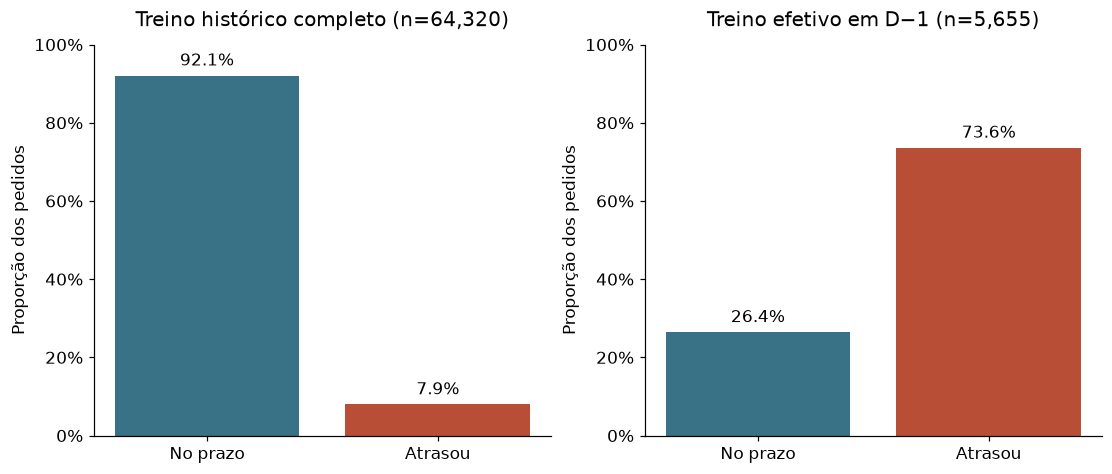

In [12]:
eda = pedidos_d1.iloc[indice_treino].copy()
treino_historico = pedidos_d1.loc[particao == "train"]
classes = pd.DataFrame({"Treino histórico completo": treino_historico.late.value_counts().reindex([0, 1], fill_value=0),
                        "Treino efetivo em D−1": eda.late.value_counts().reindex([0, 1], fill_value=0)})
classes.index = ["No prazo", "Atrasou"]
display(classes)
fig, eixos = plt.subplots(1, 2, figsize=(10, 4.2), layout="constrained")
for ax, nome in zip(eixos, classes.columns):
    proporcao = classes[nome] / classes[nome].sum()
    barras = ax.bar(proporcao.index, proporcao, color=[CORES["pontual"], CORES["atraso"]])
    ax.bar_label(barras, labels=[f"{v:.1%}" for v in proporcao], padding=4)
    ax.set(title=f"{nome} (n={classes[nome].sum():,})", ylabel="Proporção dos pedidos", ylim=(0, 1))
    ax.yaxis.set_major_formatter(PercentFormatter(1))
plt.show()
print("Leitura: condicionar a pedidos ainda pendentes muda a frequência do alvo.")
print("Não compare diretamente essas proporções com as da antiga MLP na aprovação.")

### 5.2. Volume e taxa de atraso variam no tempo?

O volume abaixo é de compras da parte histórica de treino, não de pedidos
recebidos por dia em produção. Meses de borda podem ser parciais e meses com
poucos pedidos produzem taxas instáveis. Por isso, meses com menos de 30 pedidos
ficam **sem ponto na curva de taxa**, mas aparecem na tabela de auditoria. Isso
não remove pedidos do treino. Meses sem compras têm volume zero e taxa indefinida.
Mudanças são associações temporais, não evidência de causa.

Meses pequenos ou sem compras (auditoria; não excluídos do treino):


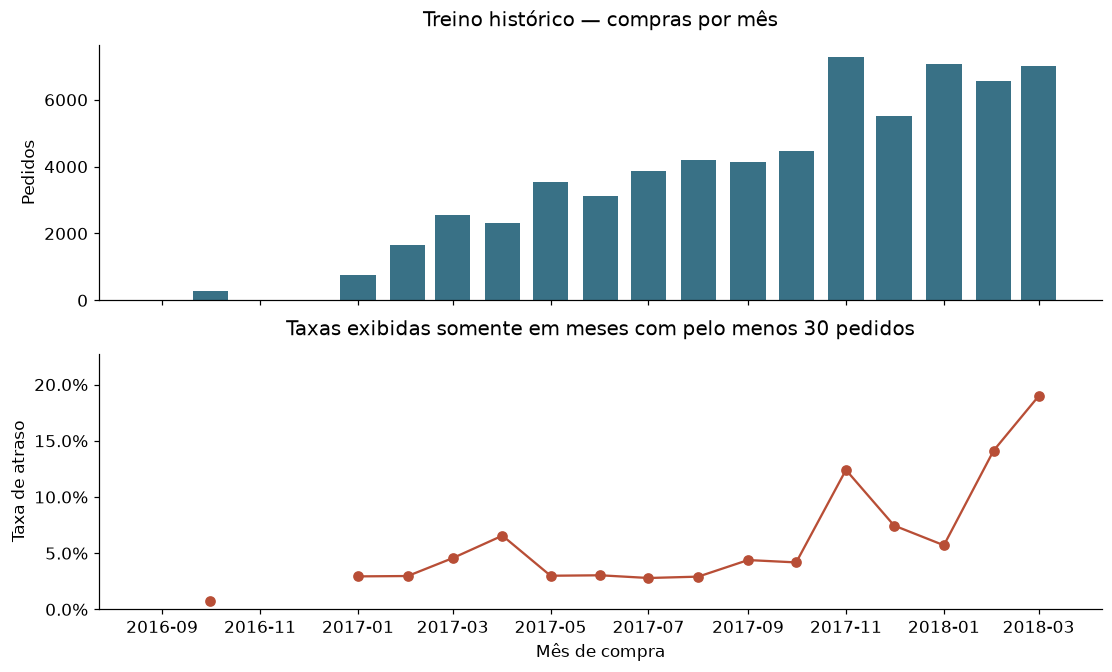

,pedidos,atrasos,taxa
2017-10,4478,187,0.0418
2017-11,7288,904,0.1240
2017-12,5513,411,0.0746
2018-01,7069,403,0.0570
2018-02,6555,926,0.1413
2018-03,7003,1328,0.1896


,pedidos,atrasos,taxa
2016-09,1,1,1.0
2016-11,0,0,NaN
2016-12,1,0,0.0


In [13]:
mensal = treino_historico.groupby(treino_historico.order_purchase_timestamp.dt.to_period("M")).agg(
    pedidos=("late", "size"), atrasos=("late", "sum"))
meses = pd.period_range(mensal.index.min(), mensal.index.max(), freq="M")
mensal = mensal.reindex(meses, fill_value=0)
mensal["taxa"] = mensal.atrasos / mensal.pedidos.replace(0, np.nan)
taxa_visivel = mensal.taxa.where(mensal.pedidos >= 30)
fig, eixos = plt.subplots(2, 1, figsize=(10, 6), sharex=True, layout="constrained")
datas = mensal.index.to_timestamp()
eixos[0].bar(datas, mensal.pedidos, width=22, color=CORES["pontual"])
eixos[0].set(title="Treino histórico — compras por mês", ylabel="Pedidos")
eixos[1].plot(datas, taxa_visivel, marker="o", color=CORES["atraso"])
eixos[1].set(title="Taxas exibidas somente em meses com pelo menos 30 pedidos",
             ylabel="Taxa de atraso", xlabel="Mês de compra",
             ylim=(0, min(1.05, max(0.15, taxa_visivel.max() * 1.2))))
eixos[1].yaxis.set_major_formatter(PercentFormatter(1))
plt.show()
display(mensal.tail(6).round(4))
print("Meses pequenos ou sem compras (auditoria; não excluídos do treino):")
display(mensal.loc[mensal.pedidos < 30].round(4))

### 5.3. Distância e peso se distribuem de forma diferente entre as classes?

Boxplots comparam os pendentes do treino efetivo. Ocultamos apenas os pontos
extremos **no desenho**, sem excluir linhas do treinamento. Dados ausentes
não são plotados; zeros decorrentes da agregação de peso continuam sendo uma
limitação da versão reproduzida. Distribuições sobrepostas impedem regras perfeitas.

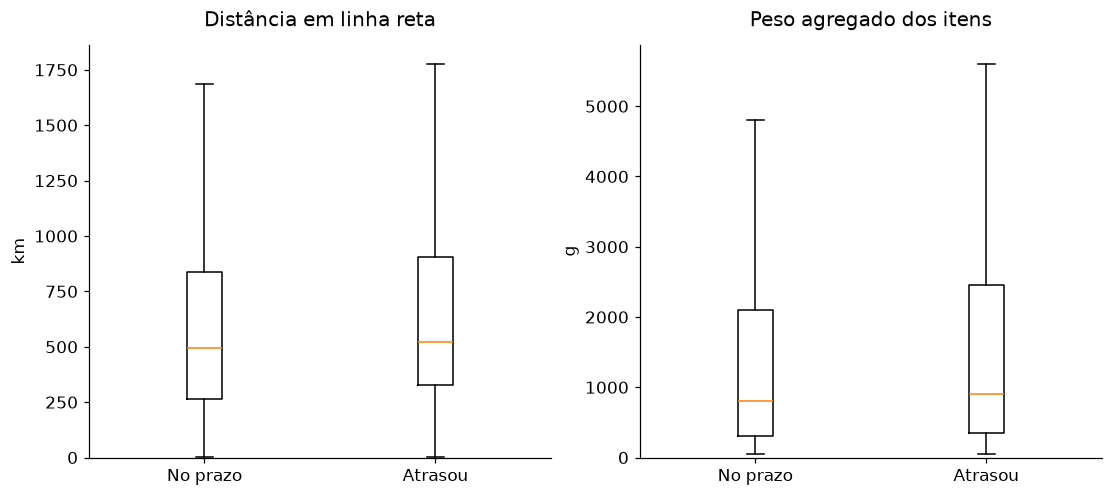

,haversine_km,weight_total,promised_days
late,,,
0,492.7,800.0,22.21
1,520.2,900.0,23.39


In [14]:
fig, eixos = plt.subplots(1, 2, figsize=(10, 4.4), layout="constrained")
for ax, coluna, titulo, unidade in [
    (eixos[0], "haversine_km", "Distância em linha reta", "km"),
    (eixos[1], "weight_total", "Peso agregado dos itens", "g")]:
    grupos = [eda.loc[eda.late.eq(classe), coluna].dropna() for classe in [0, 1]]
    ax.boxplot(grupos, tick_labels=["No prazo", "Atrasou"], showfliers=False)
    ax.set(title=titulo, ylabel=unidade, ylim=(0, None))
plt.show()
display(eda.groupby("late")[["haversine_km", "weight_total", "promised_days"]].median().round(2))

## 6. Formar os atributos que os modelos podem receber

### 6.1. Atributos básicos e históricos

`X` contém as características; `y` contém o resultado observado. Não são a mesma
coisa. [`feature_table`](../experimentos/EntregaCertaAI_VER07/src/support/olist_checkpoint.py)
seleciona uma lista explícita de atributos disponíveis no checkpoint.
[`enhanced_features`](../experimentos/EntregaCertaAI_VER07/src/support/ver04_features.py)
adiciona janelas históricas de 30/90 dias e relações logísticas.

Históricos podem se atualizar com entregas conhecidas antes de **cada** checkpoint,
inclusive durante a validação/teste. Isso simula consulta operacional; não retreina
o modelo nem permite usar entregas futuras. As taxas usam suavização fixa, não
uma média calculada com rótulos de todo o dataset.


In [15]:
X_basico, _ = checkpoint.feature_table(pedidos_d1)
X_historicos = historicos.enhanced_features(pedidos_d1, X_basico)
etapas_atributos = {"Básicos e histórico acumulado": X_basico.shape[1],
                    "Janelas e relações logísticas": X_historicos.shape[1]}

# Auditoria amostral independente: só entregas anteriores podem contar no histórico.
amostra = eda.sample(n=min(12, len(eda)), random_state=SEMENTE)
for _, pedido in amostra.iterrows():
    passado = base.loc[base.seller_id.eq(pedido.seller_id)
                       & (base.order_delivered_customer_date < pedido.checkpoint_at)]
    assert pedido.seller_hist_n == len(passado)
    assert pedido.seller_hist_late_n == passado.late.sum()
print("Histórico de vendedor conferido em", len(amostra), "pedidos reais do treino.")

Histórico de vendedor conferido em 12 pedidos reais do treino.


### 6.2. Marketing com informação anterior à compra

O piloto escolhido usa apenas negócios fechados (`closed_only`), não a variante
com MQL. A junção por vendedor aceita somente `won_date <= compra`. Ausências
permanecem ausências. A cobertura baixa limita o que se pode concluir sobre marketing.

In [16]:
marketing, cobertura_marketing = externos.add_marketing(base, PREPARADOS / "olist_closed_deals_dataset.csv")
assert marketing.order_id.equals(base.order_id)
display(pd.Series(cobertura_marketing, name="Marketing — cobertura na coorte").to_frame())

,Marketing — cobertura na coorte
rows_in_source,842.000000
covered_orders_with_prior_win,4409.000000
covered_pct,4.570333


### 6.3. Rodovias e clima histórico publicado

Distâncias rodoviárias são obtidas por municípios, a partir da rede de **maio
de 2024**. Não são distâncias históricas exatas de 2016–2018. O arquivo é lido
em blocos para reduzir memória; esta célula pode demorar alguns minutos.

Clima usa observações agregadas por UF e sua data de disponibilidade. A hipótese
de publicação (sete dias, quando necessária) não é uma medição de latência real.
Não são previsões de chuva futura nem condições exatas da rota do caminhão.

In [17]:
rodovias, cobertura_rodovias = externos.add_roads(base, ARQUIVO_RODOVIAS, PREPARADOS / "municipios_ibge.csv")
clima, cobertura_clima = externos.add_weather(pedidos_d1, PREPARADOS / "weather_daily.csv")
for tabela in [rodovias, clima]:
    assert tabela.order_id.equals(base.order_id)
coberturas = {"marketing": cobertura_marketing, "rodovias": cobertura_rodovias, "clima": cobertura_clima}
display(pd.DataFrame({"Fonte": ["Marketing anterior", "Rodovias 2024", "Chuva UF de destino"],
                       "Cobertura (%)": [cobertura_marketing["covered_pct"], cobertura_rodovias["matched_pct"],
                                           cobertura_clima["customer_weather_coverage_pct"]]}).round(2))

,Fonte,Cobertura (%)
0,Marketing anterior,4.57
1,Rodovias 2024,15.70
2,Chuva UF de destino,99.99


### 6.4. Construir os 111 atributos iniciais

As tabelas externas são alinhadas por `order_id` antes da concatenação.
`add_practical_features` adiciona médias históricas e relações logísticas.
Números infinitos viram ausentes; categorias ausentes recebem `__MISSING__`.
Nesta etapa, `X_completo` guarda as 111 colunas originais para auditoria e para o
primeiro CatBoost. Na seção 7, **`X` será efetivamente reduzido e `X_treino` reconstruído**.

CatBoost trata categorias e nulos numéricos nativamente. Random Forest e Regressão
Logística usarão pipelines ajustados exclusivamente no treino: imputação e one-hot;
a regressão logística também padroniza os números. A quantidade após one-hot não
deve ser confundida com a quantidade de atributos originais.


In [18]:
X_enriquecido = pd.concat([X_historicos, marketing.drop(columns="order_id"),
                           rodovias.drop(columns="order_id"), clima.drop(columns="order_id")], axis=1)
X_enriquecido = ver06.clean_categorical(X_enriquecido)
X = ver07.add_practical_features(pedidos_d1, X_enriquecido)
categoricas = X.select_dtypes(include=["object", "string", "category"]).columns.tolist()
numericas = [c for c in X if c not in categoricas]
etapas_atributos["Com fontes externas"] = X_enriquecido.shape[1]
etapas_atributos["VER0.7 final"] = X.shape[1]

proibidas = {"late", "atrasou", "order_delivered_customer_date", "order_delivered_carrier_date",
             "order_status", "review_score", "order_id", "real_delay_days", "real_transit_days"}
assert not proibidas.intersection(X.columns)
assert X.columns.is_unique and X.shape == (len(base), 111)
assert not np.isinf(X[numericas].to_numpy(dtype=float)).any()
modelo_recebido = CatBoostClassifier()
modelo_recebido.load_model(str(PACOTE / "results/pilot_Dminus1_CB07_closed_only.cbm"))
assert X.columns.tolist() == modelo_recebido.feature_names_
assert categoricas == [X.columns[i] for i in modelo_recebido.get_cat_feature_indices()]
display(pd.Series(etapas_atributos, name="Quantidade de atributos").to_frame())
print("Categorias:", len(categoricas), "| Numéricos:", len(numericas))

# Snapshot anterior à seleção: permite repetir a seção 7 sem exclusões cumulativas.
X_completo = X.copy()
categoricas_completas = categoricas.copy()
numericas_completas = numericas.copy()


Categorias: 12 | Numéricos: 99


,Quantidade de atributos
Básicos e histórico acumulado,57
Janelas e relações logísticas,78
Com fontes externas,95
VER0.7 final,111


### 6.5. Onde faltam informações no treino?

Para categorias, o marcador `__MISSING__` também conta como ausência. Não
preenchemos a matriz rodoviária ou marketing com registros inventados. Um campo
com muita falta pode funcionar como indicador de cobertura, sem representar
um efeito causal da variável original.

Nulos numéricos são permitidos; textos categóricos ausentes já foram identificados.
<class 'pandas.core.frame.DataFrame'>
Index: 5655 entries, 0 to 63976
Columns: 111 entries, promised_days to route_avg_transit_minus_elapsed
dtypes: bool(3), float32(20), float64(57), int32(8), int64(3), int8(8), object(12)
memory usage: 3.8+ MB
promised_days                       0.000000
payment_delay_hours                 0.000177
freight_ratio                       0.000000
price_per_kg                        0.000000
purchase_dow                        0.000000
                                      ...   
road_km_per_promised_day_2024       0.861892
shipment_after_limit_known_days     0.046861
customer_seller_price_per_km        0.005659
seller_avg_transit_minus_elapsed    0.114058
route_avg_transit_minus_elapsed     0.058709
Length: 111, dtype: float64


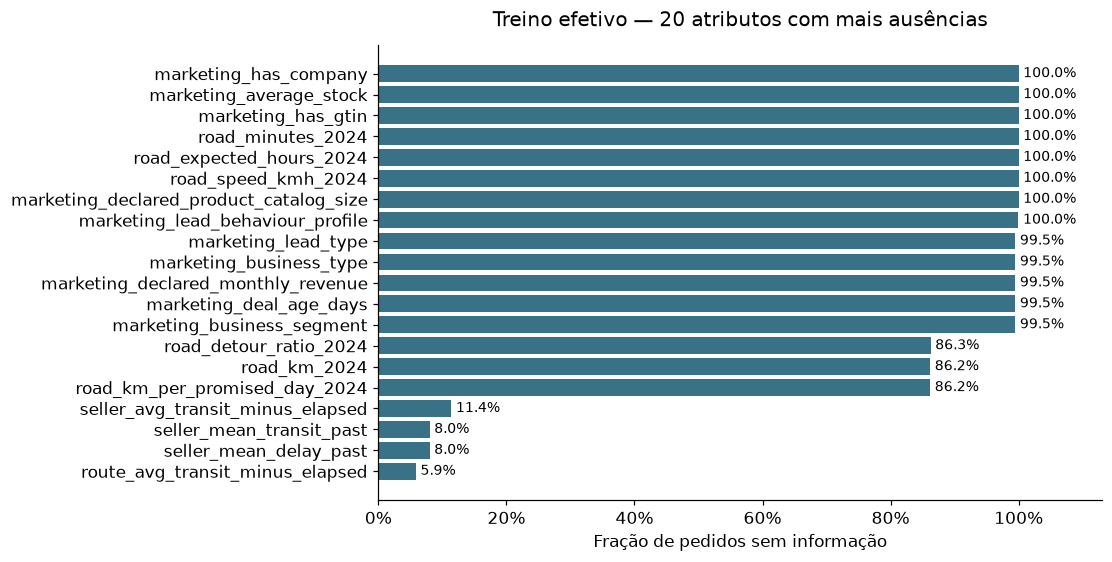

In [19]:
X_treino = X.iloc[indice_treino].copy()
y_treino = y[indice_treino]
ausencias = X_treino.isna().mean()
ausencias.loc[categoricas] = X_treino[categoricas].eq("__MISSING__").mean()
mais_ausentes = ausencias.sort_values(ascending=False).head(20).sort_values()
fig, ax = plt.subplots(figsize=(10, 5), layout="constrained")
barras = ax.barh(mais_ausentes.index, mais_ausentes, color=CORES["pontual"])
ax.bar_label(barras, labels=[f"{v:.1%}" for v in mais_ausentes], padding=3, fontsize=9)
ax.set(title="Treino efetivo — 20 atributos com mais ausências", xlabel="Fração de pedidos sem informação", xlim=(0, 1.13))
ax.xaxis.set_major_formatter(PercentFormatter(1))
plt.show()
print("Nulos numéricos são permitidos; textos categóricos ausentes já foram identificados.")

X_treino.info()
print(ausencias)


### 6.6. Mapa das junções e disponibilidade dos dados

Uma linha final representa um pedido. Itens e pagamentos são resumidos **antes** de
serem unidos aos pedidos, evitando que um produto cartesiano infle preço, peso e frete.

| Fontes / operação | Chave e cardinalidade | Tratamento e controle |
|---|---|---|
| Itens ← produtos | `product_id`, muitos para um, left | Volume = comprimento × altura × largura; depois soma/média por `order_id`. |
| Pedidos ← resumo dos itens | `order_id`, um para um, left | Soma de preço/frete/peso/volume, médias de descrição/fotos; prazo de envio máximo. Vendedor e categoria do primeiro item por `order_item_id`. |
| Pedidos ← pagamentos agregados | `order_id`, um para um, left | Soma de valores, quantidade de pagamentos, maior parcelamento; tipo do primeiro pagamento por sequencial. |
| Pedidos ← clientes | `customer_id`, muitos para um, left | UF, cidade e prefixo de CEP do destinatário. |
| Pedidos ← vendedores | `seller_id`, muitos para um, left | Cadastro do vendedor de referência do primeiro item. |
| Cliente/vendedor ← geolocalização | Prefixo de CEP, muitos para um, left | Mediana das coordenadas válidas por prefixo; latitude −35 a 6, longitude −75 a −32. |
| Históricos acumulados e médias | `seller_id`, `route_state` ou `category` + tempo | `merge_asof` para trás: só entregas **estritamente anteriores** ao checkpoint. Reassocia por `order_id`/posição original. |
| Históricos em janelas | Mesmas chaves + checkpoint e checkpoint − 30/90 dias | Diferença entre contagens acumuladas; intervalo efetivo `[checkpoint − janela, checkpoint)`. |
| Marketing ← negócios fechados | `seller_id` + tempo, asof para trás | Último `won_date <= compra`; mantém ausências quando não há negócio anterior. |
| Municípios IBGE ← cidade/UF | UF + nome normalizado | Remove acentos/pontuação; descarta chaves ambíguas; cadastro parcial. |
| Rodovias ← municípios | Par dirigido código IBGE vendedor → cliente, muitos para um | Rede de maio/2024: distância em metros / 1000, duração em minutos; proxy posterior aos pedidos. |
| Clima ← UF de cada lado | UF + `available_at <= checkpoint`, asof para trás | Janela de 7 dias observados, pelo menos 5 válidos; soma de chuva, média de temperatura. Se não houver data de publicação, usa data + 7 dias. |
| Matriz final ← tabelas externas | Alinhamento por `order_id` validado, depois `concat(axis=1)` | Preserva exatamente a ordem das linhas. IDs, alvo e datas de entrega futura não entram em `X`. |

Cadastros e pagamentos não têm histórico completo de alterações; sua disponibilidade
no checkpoint é uma hipótese herdada do 03. Ausências não são registros sintéticos.

### 6.7. Dicionário dos 20 principais atributos do CatBoost do notebook 03

**Ranking de referência, anterior à seleção deste notebook.** As células de gráfico
do arquivo 03 consultado contêm erros salvos, portanto recuperamos as importâncias
com `get_feature_importance()` do modelo da execução indicada na saída final do 03:
`Modelos/notebook_ver07/20261117_231715_acb863/catboost_treinado.cbm`.
SHA-256: `a980cf1009692147c01896a22c7801aa3b370fb8c62ddc4184ac34d9127fde57`.
O ranking está incorporado abaixo, sem depender desse arquivo para executar o 04.

Importância = `PredictionValuesChange`, em pontos de um total de 100; não informa
direção do efeito nem causalidade. As fórmulas foram conferidas no código local:
[checkpoint e históricos](../experimentos/EntregaCertaAI_VER07/src/support/olist_checkpoint.py),
[janelas e interações](../experimentos/EntregaCertaAI_VER07/src/support/ver04_features.py),
[fontes externas](../experimentos/EntregaCertaAI_VER07/src/support/external_features.py) e
[atributos VER0.7](../experimentos/EntregaCertaAI_VER07/src/benchmark_ver07.py).

| Posição | Coluna | Importância no 03 | Para que serve | Cálculo e origem |
|---|---|---:|---|---|
| 1 | `route_avg_transit_minus_elapsed` | 5.773502 | Margem de trânsito da rota (dias) | Média histórica de dias entre despacho e entrega na rota UF vendedor → UF cliente, menos `in_transit_days` do pedido. Histórico só de entregues antes do checkpoint, ao menos 4 observações válidas, trânsito entre 0 e 180 dias; sem despacho conhecido, fica ausente. |
| 2 | `checkpoint_dow` | 3.746604 | Dia da semana da análise | `checkpoint_at = normalize(data prometida) − 1 dia`; `.dt.dayofweek`, segunda = 0 e domingo = 6. |
| 3 | `shipment_after_limit_known_days` | 3.420261 | Desvio do prazo de despacho (dias) | (Data de despacho − `shipping_limit`) / 86400 segundos. `shipping_limit` é o maior prazo de envio dos itens; só preenchido se o despacho já era conhecido. Positivo = despachado depois do limite. |
| 4 | `promise_dow` | 3.120040 | Dia da semana prometido | Dia da semana de `order_estimated_delivery_date`, segunda = 0 a domingo = 6. |
| 5 | `volume_total` | 2.965995 | Volume agregado (cm³) | Itens unidos a produtos por `product_id`; comprimento × altura × largura de cada item e soma por `order_id`. A soma ignora nulos e pode resultar em zero quando todos faltam. |
| 6 | `seller_mean_transit_past` | 2.545930 | Trânsito médio histórico do vendedor (dias) | Média de (entrega − despacho) / 86400 para o vendedor do primeiro item, apenas entregas anteriores ao checkpoint. Exclui trânsito negativo e acima de 180 dias; exige pelo menos 4 registros válidos. |
| 7 | `seller_rain_7d_published_mm` | 2.249107 | Chuva publicada na UF de origem (mm) | Soma de precipitação na janela de 7 dias observados, mínimo 5 válidos; junção asof por UF do vendedor com a última publicação disponível no checkpoint. Proxy estadual, não chuva da rota. |
| 8 | `customer_state` | 2.246123 | UF de destino | Campo do cadastro de clientes unido por `customer_id`. Categoria textual; ausências viram `__MISSING__`. |
| 9 | `seller_temp_7d_published_c` | 2.000272 | Temperatura publicada na UF de origem (°C) | Média de temperatura dos 7 dias observados, mínimo 5 válidos, última publicação disponível até o checkpoint, por UF do vendedor. |
| 10 | `category_hist_rate` | 1.921693 | Taxa histórica suavizada da categoria | (Atrasos históricos + 0,8) / (entregas históricas + 12). Categoria do primeiro item; só desfechos anteriores ao checkpoint via `merge_asof`. |
| 11 | `purchase_hour` | 1.811487 | Hora da compra | `.dt.hour` de `order_purchase_timestamp`, de 0 a 23, conforme os timestamps da fonte (sem conversão de fuso). |
| 12 | `time_before_due_when_dispatched` | 1.794352 | Folga entre despacho e promessa (dias) | (Data prometida − data de despacho) / 86400 segundos. Só quando o despacho era conhecido no checkpoint. Pode ser negativa. |
| 13 | `days_to_next_holiday` | 1.790529 | Dias até próximo feriado do calendário do pacote | Menor diferença em dias entre checkpoint e feriado na mesma data ou futuro, limitada a 30; sem feriado futuro retorna 30. Calendário 2016–2019 com datas fixas e móveis (Carnaval, Sexta Santa, Corpus Christi); não inclui todos os feriados locais. |
| 14 | `description_len_avg` | 1.755942 | Tamanho médio das descrições | Média de `product_description_lenght` dos produtos dos itens, após junção por `product_id` e agrupamento por `order_id`; ignora nulos. |
| 15 | `route_late_90d` | 1.748733 | Atrasos observados na rota nos últimos 90 dias | Contagem de entregas atrasadas da mesma rota de UFs em `[checkpoint − 90 dias, checkpoint)`, por diferença de contagens acumuladas em duas junções asof. Não é taxa. |
| 16 | `customer_rain_7d_published_mm` | 1.721917 | Chuva publicada na UF de destino (mm) | Soma na janela de 7 dias observados, mínimo 5 válidos; asof por UF do cliente, somente publicação disponível até o checkpoint. |
| 17 | `route_hist_rate` | 1.624676 | Taxa histórica suavizada da rota | (Atrasos anteriores da rota + 0,8) / (entregas anteriores da rota + 12). `route_state = seller_state + "__" + customer_state`; histórico estritamente anterior ao checkpoint. |
| 18 | `not_dispatched` | 1.583201 | Despacho ainda não conhecido | Negação de `carrier_known`: verdadeiro quando a data de despacho falta ou é posterior ao checkpoint. Usa o estado conhecido na análise, não o estado final. |
| 19 | `customer_temp_7d_published_c` | 1.566337 | Temperatura publicada na UF de destino (°C) | Média na janela de 7 dias observados, mínimo 5 válidos; última publicação disponível por UF do cliente até o checkpoint. |
| 20 | `km_weight_interaction` | 1.551941 | Interação distância × peso (km·kg) | `haversine_km × max(weight_total, 0) / 1000`. Haversine usa medianas de coordenadas dos CEPs de vendedor/cliente; peso é soma dos pesos dos itens em gramas. Não representa distância rodoviária. |

Os quatro campos de clima resumem observações publicadas; não são previsões do clima futuro.
As médias históricas e taxas usam somente resultados já conhecidos em cada checkpoint.

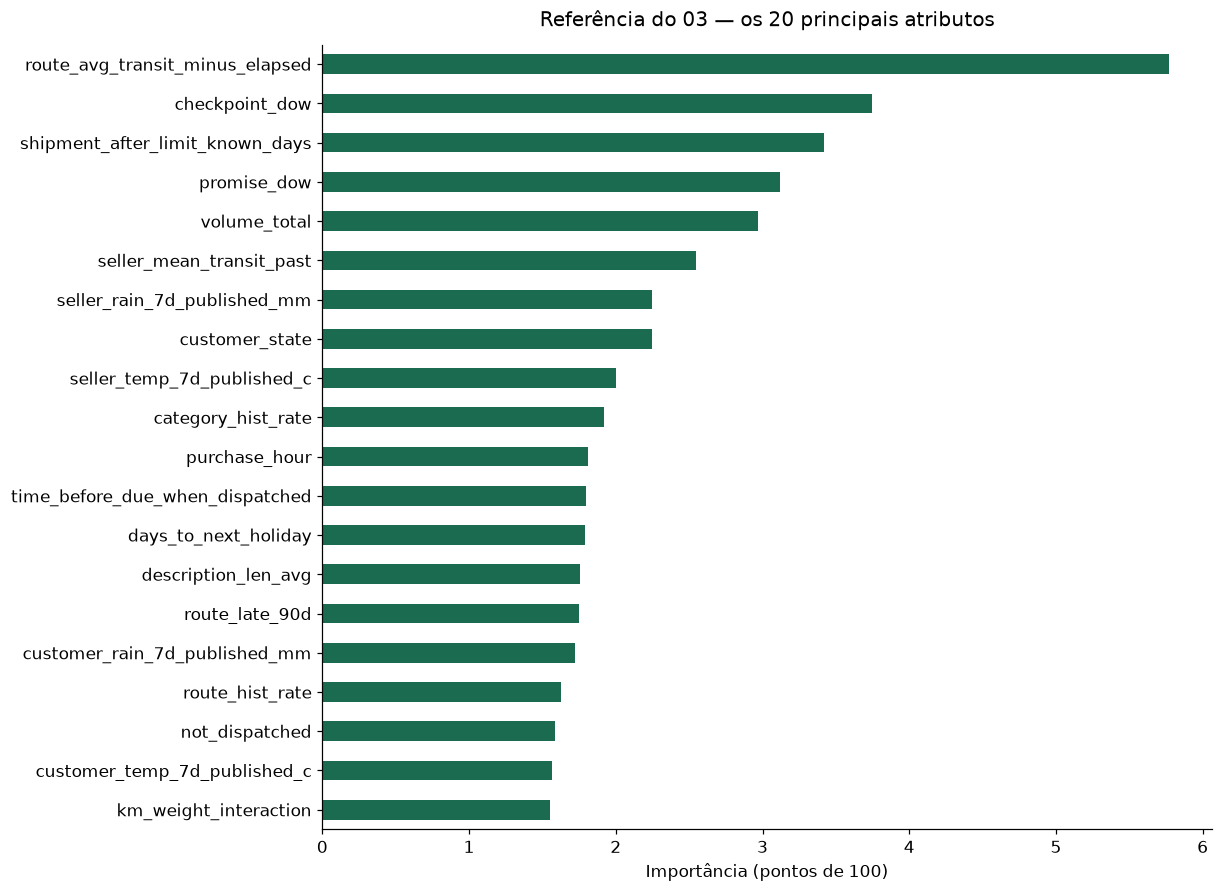

In [20]:
top20_referencia_03 = pd.Series({'route_avg_transit_minus_elapsed': 5.7735017182823105, 'checkpoint_dow': 3.7466038267743755, 'shipment_after_limit_known_days': 3.4202608677722646, 'promise_dow': 3.1200401045953625, 'volume_total': 2.965994715394013, 'seller_mean_transit_past': 2.54593045215779, 'seller_rain_7d_published_mm': 2.249106694204842, 'customer_state': 2.24612327347879, 'seller_temp_7d_published_c': 2.0002715623156364, 'category_hist_rate': 1.9216926056659933, 'purchase_hour': 1.811486535468182, 'time_before_due_when_dispatched': 1.7943516480042945, 'days_to_next_holiday': 1.7905290487030638, 'description_len_avg': 1.7559416329605657, 'route_late_90d': 1.748732675513327, 'customer_rain_7d_published_mm': 1.7219174144313376, 'route_hist_rate': 1.6246758034358653, 'not_dispatched': 1.5832005689113566, 'customer_temp_7d_published_c': 1.5663369089445003, 'km_weight_interaction': 1.5519408647989537}, name="Importância no 03")
fig, ax = plt.subplots(figsize=(11, 8), layout="constrained")
top20_referencia_03.sort_values().plot.barh(ax=ax, color=CORES["modelo"])
ax.set(title="Referência do 03 — os 20 principais atributos", xlabel="Importância (pontos de 100)")
plt.show()


## 7. Treinar uma vez para selecionar e depois comparar três modelos

### 7.1. Primeiro CatBoost: diagnóstico apenas com o treino

Treinamos com as 111 colunas, mesma seed e parâmetros do 03. A importância é
calculada nesse modelo usando apenas o treino; validação e teste não escolhem colunas.
Removemos importância **menor que `LIMIAR_IMPORTANCIA` (0,4 ponto)**, inclusive zero.
A tabela também mostra ausências >80%, mas esse indicador não é condição de remoção.
Baixa importância não comprova irrelevância: atributos correlacionados podem dividir crédito.

`X_completo` é preservado para auditoria; **`X` recebe o drop**, e `X_treino`, `categoricas`
e `numericas` são atualizados juntos. Assim, todos os treinos seguintes usam a mesma matriz
reduzida. Reexecutar esta seção parte sempre de `X_completo`, sem remoções cumulativas.

Primeiro CatBoost: 6.5s. Removidas 34 de 111 colunas.
Colunas removidas: ['n_items', 'n_sellers', 'photos_avg', 'payments_n', 'same_state', 'has_geo', 'approval_known', 'dispatch_late_to_shipping_limit', 'checkpoint_year', 'promised_holiday', 'payment_type', 'route_hist_n', 'seller_late_30d', 'seller_late_90d', 'geo_east_west_sign', 'same_city', 'days_fulfillment_margin', 'marketing_has_prior_deal', 'marketing_deal_age_days', 'marketing_business_segment', 'marketing_lead_type', 'marketing_lead_behaviour_profile', 'marketing_has_company', 'marketing_has_gtin', 'marketing_average_stock', 'marketing_business_type', 'marketing_declared_product_catalog_size', 'marketing_declared_monthly_revenue', 'road_km_2024', 'road_minutes_2024', 'road_detour_ratio_2024', 'road_expected_hours_2024', 'road_speed_kmh_2024', 'road_km_per_promised_day_2024']
Importância somada removida: 2.8423 pontos.
X e X_treino atualizados: 77 atributos; 4 categóricos e 73 numéricos.


,importancia,fracao_ausente,mais_80pct_ausente,remover
approval_known,0.000000,0.000000,False,True
has_geo,0.000000,0.000000,False,True
promised_holiday,0.000000,0.000000,False,True
dispatch_late_to_shipping_limit,0.000000,0.000000,False,True
road_speed_kmh_2024,0.000000,1.000000,True,True
road_expected_hours_2024,0.000000,1.000000,True,True
road_minutes_2024,0.000000,1.000000,True,True
marketing_declared_monthly_revenue,0.000000,0.994872,True,True
marketing_has_company,0.000000,1.000000,True,True
marketing_lead_behaviour_profile,0.000000,0.999823,True,True


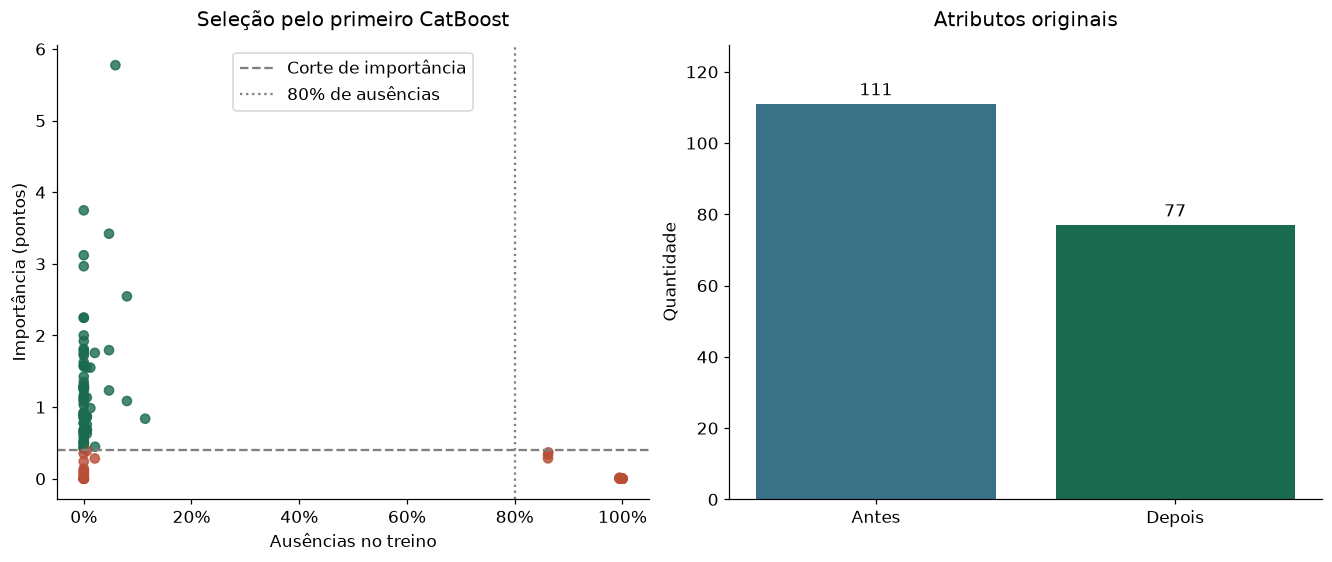

In [21]:
assert 0 <= LIMIAR_IMPORTANCIA < 100
inicio_selecao = perf_counter()
modelo_inicial = CatBoostClassifier(**PARAMETROS)
modelo_inicial.fit(X_completo.iloc[indice_treino], y[indice_treino], cat_features=categoricas_completas)
tempo_selecao = perf_counter() - inicio_selecao
importancias_iniciais = pd.Series(modelo_inicial.get_feature_importance(),
                                  index=modelo_inicial.feature_names_, name="importancia")
ausencias_iniciais = X_completo.iloc[indice_treino].isna().mean()
ausencias_iniciais.loc[categoricas_completas] = X_completo.iloc[indice_treino][categoricas_completas].eq("__MISSING__").mean()
tabela_selecao = pd.concat([importancias_iniciais, ausencias_iniciais.rename("fracao_ausente")], axis=1)
tabela_selecao["mais_80pct_ausente"] = tabela_selecao.fracao_ausente.gt(0.80)
tabela_selecao["remover"] = tabela_selecao.importancia.lt(LIMIAR_IMPORTANCIA)
colunas_removidas = tabela_selecao.index[tabela_selecao.remover].tolist()
assert len(colunas_removidas) < X_completo.shape[1], "O corte removeria todos os atributos."
X = X_completo.drop(columns=colunas_removidas).copy()
categoricas = [c for c in categoricas_completas if c in X.columns]
numericas = [c for c in X.columns if c not in categoricas]
X_treino = X.iloc[indice_treino].copy()
y_treino = y[indice_treino]
assert X_treino.columns.equals(X.columns) and not set(colunas_removidas).intersection(X.columns)
assert X.index.equals(X_completo.index) and len(X) == len(y)
with pd.option_context("display.max_rows", None):
    display(tabela_selecao.sort_values("importancia").round(6))
print(f"Primeiro CatBoost: {tempo_selecao:.1f}s. Removidas {len(colunas_removidas)} de {X_completo.shape[1]} colunas.")
print("Colunas removidas:", colunas_removidas)
print(f"Importância somada removida: {tabela_selecao.loc[colunas_removidas, 'importancia'].sum():.4f} pontos.")
print(f"X e X_treino atualizados: {X.shape[1]} atributos; {len(categoricas)} categóricos e {len(numericas)} numéricos.")
fig, eixos = plt.subplots(1, 2, figsize=(12, 5), layout="constrained")
eixos[0].scatter(tabela_selecao.fracao_ausente, tabela_selecao.importancia,
    c=np.where(tabela_selecao.remover, CORES["atraso"], CORES["modelo"]), alpha=0.8)
eixos[0].axhline(LIMIAR_IMPORTANCIA, color="gray", linestyle="--", label="Corte de importância")
eixos[0].axvline(0.8, color="gray", linestyle=":", label="80% de ausências")
eixos[0].xaxis.set_major_formatter(PercentFormatter(1))
eixos[0].set(title="Seleção pelo primeiro CatBoost", xlabel="Ausências no treino", ylabel="Importância (pontos)")
eixos[0].legend()
barras = eixos[1].bar(["Antes", "Depois"], [X_completo.shape[1], X.shape[1]], color=[CORES["pontual"], CORES["modelo"]])
eixos[1].bar_label(barras, padding=3)
eixos[1].set(title="Atributos originais", ylabel="Quantidade", ylim=(0, X_completo.shape[1] * 1.15))
plt.show()


### 7.2. Treino dos três modelos na matriz reduzida

| Modelo | Como aprende | Preparação |
|---|---|---|
| CatBoost | Árvores em sequência corrigem a perda anterior; 420 iterações, profundidade 5. | Categorias nativas e nulos numéricos; mesmos parâmetros do primeiro treino. |
| Random Forest | Combina 400 árvores construídas com amostras bootstrap; profundidade máxima 16 e mínimo 5 registros por folha. | Mediana + indicadores de nulos; one-hot de categorias; sem padronização. |
| Regressão Logística | Combinação linear dos atributos no logaritmo das chances, convertida em probabilidade por sigmoid; regularização L2, C=1. | Mediana + indicadores de nulos, padronização numérica e one-hot. |

Os três usam os mesmos pedidos/colunas de origem, pesos de classe balanceados e seed 42.
Imputação, escalas e vocabulário de categorias são aprendidos **somente no fit do treino**;
categorias inéditas são ignoradas pelo one-hot. Cada pipeline tem seu próprio preprocessador.
Medianas são recursos do algoritmo, não observações reais inseridas no dataset original.
O tempo mostrado inclui o preprocessamento no fit, mas exclui a etapa comum de seleção.
Hiperparâmetros são fixos; não há busca pelo melhor resultado no teste.

CatBoost: 5,655 pedidos, 77 atributos originais, 6.56s.
Random Forest: 5,655 pedidos, 77 atributos originais, 4.35s.
Regressão Logística: 5,655 pedidos, 77 atributos originais, 0.84s.
Iterações da regressão logística: [434]
Queda da perda de treino não garante generalização; avaliaremos períodos posteriores.


,Atributos originais,Entradas após preparação,Tempo de treino (s)
Modelo,,,
CatBoost,77,77,6.556
Random Forest,77,398,4.348
Regressão Logística,77,398,0.837


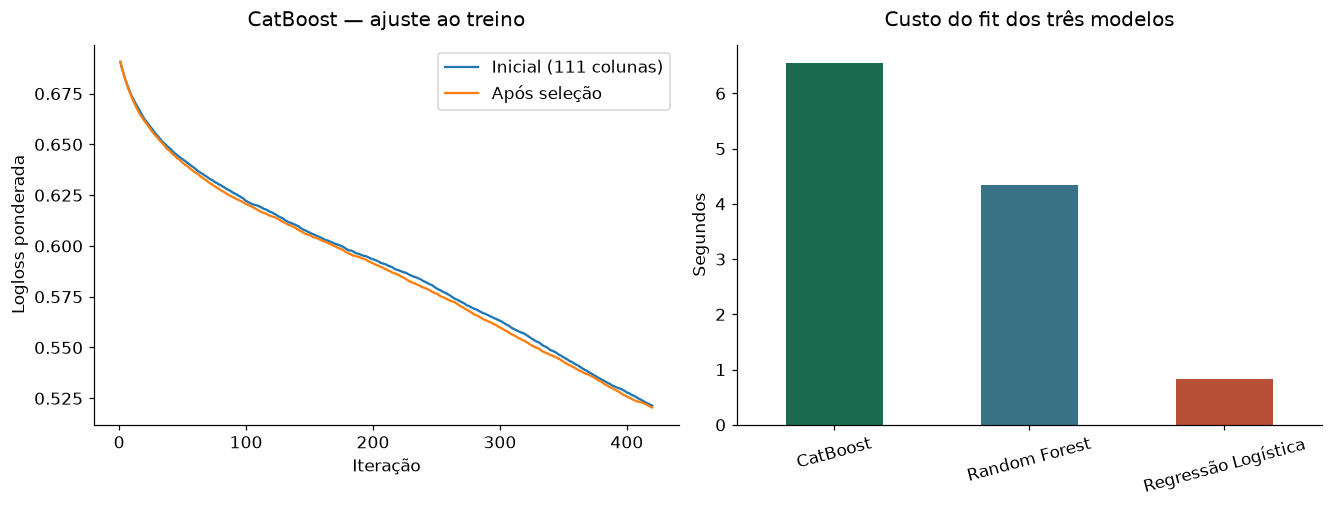

In [22]:
def criar_preprocessador(padronizar=False):
    passos = [("imputar", SimpleImputer(strategy="median", add_indicator=True, keep_empty_features=True))]
    if padronizar:
        passos.append(("padronizar", StandardScaler()))
    return ColumnTransformer([
        ("numericas", Pipeline(passos), numericas),
        ("categoricas", OneHotEncoder(handle_unknown="ignore", sparse_output=True), categoricas)
    ], sparse_threshold=1.0)

PARAMETROS_RF = dict(n_estimators=400, max_depth=16, min_samples_leaf=5,
                     max_features="sqrt", class_weight="balanced", random_state=SEMENTE, n_jobs=4)
PARAMETROS_LINEAR = dict(C=1.0, solver="lbfgs", max_iter=3000, tol=1e-6,
                         class_weight="balanced", random_state=SEMENTE)
modelos = {
    "CatBoost": CatBoostClassifier(**PARAMETROS),
    "Random Forest": Pipeline([("preprocessar", criar_preprocessador()),
                               ("classificador", RandomForestClassifier(**PARAMETROS_RF))]),
    "Regressão Logística": Pipeline([("preprocessar", criar_preprocessador(padronizar=True)),
                                      ("classificador", LogisticRegression(**PARAMETROS_LINEAR))])
}
tempos_treino = {}
for nome, estimador in modelos.items():
    inicio = perf_counter()
    with warnings.catch_warnings():
        warnings.simplefilter("error", ConvergenceWarning)
        if nome == "CatBoost":
            estimador.fit(X_treino, y_treino, cat_features=categoricas)
        else:
            estimador.fit(X_treino, y_treino)
    tempos_treino[nome] = perf_counter() - inicio
    print(f"{nome}: {len(X_treino):,} pedidos, {X.shape[1]} atributos originais, {tempos_treino[nome]:.2f}s.")
modelo = modelos["CatBoost"]
tabela_treino = pd.DataFrame([
    {"Modelo": nome, "Atributos originais": X.shape[1],
     "Entradas após preparação": X.shape[1] if nome == "CatBoost" else len(est.named_steps["preprocessar"].get_feature_names_out()),
     "Tempo de treino (s)": tempos_treino[nome]}
    for nome, est in modelos.items()
]).set_index("Modelo")
display(tabela_treino.round(3))
print("Iterações da regressão logística:", modelos["Regressão Logística"].named_steps["classificador"].n_iter_)
fig, eixos = plt.subplots(1, 2, figsize=(12, 4.5), layout="constrained")
for titulo, est in [("Inicial (111 colunas)", modelo_inicial), ("Após seleção", modelo)]:
    perdas = est.get_evals_result()["learn"]["Logloss"]
    eixos[0].plot(np.arange(1, len(perdas)+1), perdas, label=titulo)
eixos[0].set(title="CatBoost — ajuste ao treino", xlabel="Iteração", ylabel="Logloss ponderada")
eixos[0].legend()
tabela_treino["Tempo de treino (s)"].plot.bar(ax=eixos[1], color=list(CORES_MODELOS.values()), rot=15)
eixos[1].set(title="Custo do fit dos três modelos", ylabel="Segundos", xlabel="")
plt.show()
print("Queda da perda de treino não garante generalização; avaliaremos períodos posteriores.")


## 8. Transformar scores em fila e avaliar a validação

### 8.1. A regra operacional é diária

O modelo gera um score; a capacidade determina a fila. Por dia, selecionamos
`ceil(0,65 × pendentes)` pelos maiores scores. `ceil` arredonda para cima:
um dia com poucos pedidos pode ultrapassar 65% efetivamente. Empates seguem a
ordem cronológica original. Um pedido já entregue não é pontuado, recebendo
zero convencional. Esse zero não significa uma probabilidade estimada.

Para os três modelos, a regra é idêntica. A AP mede o ranking nos pendentes;
precision/recall/F1 medem a fila escolhida. Acurácia total também inclui pedidos
já entregues; por isso exibimos separadamente acurácia nos pendentes.

In [23]:
def fila_diaria(scores, idx):
    fila = pd.DataFrame({"posicao": np.arange(len(idx)), "score": scores,
                         "pendente": pendente[idx],
                         "dia": pedidos_d1.checkpoint_at.iloc[idx].to_numpy()})
    alertas = np.zeros(len(idx), dtype=int)
    for _, grupo in fila.loc[fila.pendente].groupby("dia", sort=False):
        quantidade = math.ceil(len(grupo) * FRACAO_FILA)
        escolhidos = grupo.sort_values(["score", "posicao"], ascending=[False, True]).head(quantidade)
        alertas[escolhidos.posicao.to_numpy()] = 1
    return alertas

def pontuar(modelo_usado, idx, matriz=None):
    matriz = X if matriz is None else matriz
    scores = np.zeros(len(idx), dtype=float)
    ativos = pendente[idx]
    scores[ativos] = modelo_usado.predict_proba(matriz.iloc[idx[ativos]])[:, 1]
    return scores

def avaliar(nome, idx, scores, alertas):
    real, ativos = y[idx], pendente[idx]
    tn, fp, fn, tp = confusion_matrix(real, alertas, labels=[0, 1]).ravel()
    return dict(modelo=nome, pedidos=len(idx), pendentes=int(ativos.sum()),
        atrasos=int(real.sum()), fila=int(alertas.sum()), tp=int(tp), fp=int(fp), fn=int(fn), tn=int(tn),
        precision=precision_score(real, alertas, zero_division=0), recall=recall_score(real, alertas, zero_division=0),
        f1=f1_score(real, alertas, zero_division=0), accuracy_total=accuracy_score(real, alertas),
        accuracy_pendentes=accuracy_score(real[ativos], alertas[ativos]),
        ap_pendentes=average_precision_score(real[ativos], scores[ativos]),
        fila_total=float(alertas.mean()), fila_pendentes=float(alertas.sum() / ativos.sum()))


def avaliar_conjunto(idx):
    scores_por_modelo, filas_por_modelo, linhas = {}, {}, []
    for nome, est in modelos.items():
        scores = pontuar(est, idx)
        assert np.isfinite(scores).all() and ((scores >= 0) & (scores <= 1)).all()
        fila = fila_diaria(scores, idx)
        np.testing.assert_array_equal(fila, ver07.top_ratio_policy(scores, pendente[idx], pedidos_d1.checkpoint_at.iloc[idx], FRACAO_FILA))
        scores_por_modelo[nome], filas_por_modelo[nome] = scores, fila
        linhas.append(avaliar(nome, idx, scores, fila))
    tabela = pd.DataFrame(linhas).set_index("modelo")
    assert tabela.fila.nunique() == 1, "Os modelos devem receber a mesma capacidade."
    return tabela, scores_por_modelo, filas_por_modelo

COLUNAS_METRICAS = ["precision", "recall", "f1", "accuracy_total", "accuracy_pendentes", "ap_pendentes"]
tabela_validacao, scores_validacao_modelos, filas_validacao_modelos = avaliar_conjunto(indice_validacao)
display(tabela_validacao[["pedidos", "pendentes", "fila", "tp", "fp", "fn", "tn"]])
display(tabela_validacao[COLUNAS_METRICAS].round(4))
modelo_escolhido_validacao = tabela_validacao.ap_pendentes.idxmax()
print("Modelo escolhido por AP na validação (critério fixo):", modelo_escolhido_validacao)

# Ablação: efeito da seleção no CatBoost; diagnóstico, sem procurar outro corte.
scores_inicial_validacao = pontuar(modelo_inicial, indice_validacao, X_completo)
metricas_inicial_validacao = avaliar("CatBoost completo", indice_validacao, scores_inicial_validacao,
                                    fila_diaria(scores_inicial_validacao, indice_validacao))
ablacao = pd.DataFrame([metricas_inicial_validacao,
    dict(tabela_validacao.loc["CatBoost"], modelo="CatBoost selecionado")]).set_index("modelo")
ablacao["atributos"] = [X_completo.shape[1], X.shape[1]]
display(ablacao[["atributos"] + COLUNAS_METRICAS].round(4))
delta_ap = float(ablacao.ap_pendentes.iloc[1] - ablacao.ap_pendentes.iloc[0])
print(f"Variação de AP após seleção na validação: {delta_ap:+.6f}.")
print("A seleção pode piorar o resultado; mantemos o corte predefinido e relatamos a diferença.")


Modelo escolhido por AP na validação (critério fixo): Random Forest
Variação de AP após seleção na validação: +0.003590.
A seleção pode piorar o resultado; mantemos o corte predefinido e relatamos a diferença.


,pedidos,pendentes,fila,tp,fp,fn,tn
modelo,,,,,,,
CatBoost,12175,1017,680,478,202,196,11299
Random Forest,12175,1017,680,490,190,184,11311
Regressão Logística,12175,1017,680,465,215,209,11286


,precision,recall,f1,accuracy_total,accuracy_pendentes,ap_pendentes
modelo,,,,,,
CatBoost,0.7029,0.7092,0.7061,0.9673,0.6087,0.7589
Random Forest,0.7206,0.7270,0.7238,0.9693,0.6323,0.7667
Regressão Logística,0.6838,0.6899,0.6869,0.9652,0.5831,0.7665


,atributos,precision,recall,f1,accuracy_total,accuracy_pendentes,ap_pendentes
modelo,,,,,,,
CatBoost completo,111,0.7059,0.7122,0.7090,0.9676,0.6126,0.7553
CatBoost selecionado,77,0.7029,0.7092,0.7061,0.9673,0.6087,0.7589


### 8.2. Comparar com regras simples usando a mesma capacidade

Uma boa comparação não é apenas “acertar todos os pontuais”. Testamos rankings
simples baseados em idade do pedido, trânsito e despacho. Todos recebem a mesma
cota diária. Escolhemos a regra com maior F1 **na validação**, não no teste.
Os scores dessas regras são ordenadores, não probabilidades.

In [24]:
regras = {
    "Idade do pedido": pedidos_d1.age_days.to_numpy(),
    "Tempo em trânsito": pedidos_d1.in_transit_days.fillna(-1).to_numpy(),
    "Não despachado, depois idade": (pedidos_d1.not_dispatched.astype(float) * 1000 + pedidos_d1.age_days.fillna(0)).to_numpy(),
    "Tempo após limite de envio": pedidos_d1.shipping_limit_age_days.fillna(-100).to_numpy(),
}
resultados_regras = []
for nome, scores in regras.items():
    alertas = fila_diaria(scores[indice_validacao], indice_validacao)
    resultados_regras.append(avaliar(nome, indice_validacao, scores[indice_validacao], alertas))
tabela_regras = pd.DataFrame(resultados_regras).set_index("modelo")
melhor_regra = tabela_regras.f1.idxmax()
display(tabela_regras[["fila", "tp", "fp", "fn", "precision", "recall", "f1"]].round(4))
print("Regra escolhida pela validação:", melhor_regra)


Regra escolhida pela validação: Tempo após limite de envio


,fila,tp,fp,fn,precision,recall,f1
modelo,,,,,,,
Idade do pedido,680,467,213,207,0.6868,0.6929,0.6898
Tempo em trânsito,680,458,222,216,0.6735,0.6795,0.6765
"Não despachado, depois idade",680,470,210,204,0.6912,0.6973,0.6942
Tempo após limite de envio,680,471,209,203,0.6926,0.6988,0.6957


## 9. Avaliar os três modelos no mesmo teste histórico

Modelos, corte de importância, cota e critério de escolha já estão definidos.
Os resultados abaixo descrevem o teste; não mudamos o modelo escolhido pela validação.
**Precision:** quantos alertas eram atrasos; **recall:** quantos atrasos encontramos;
**F1:** equilíbrio dos dois; **AP:** qualidade do ranking nos pendentes, em vários cortes.
As métricas são frações de 0 a 1. A mesma fila diária garante comparação de capacidade.

In [25]:
tabela_teste, scores_teste_modelos, filas_teste_modelos = avaliar_conjunto(indice_teste)
ativos_teste = pendente[indice_teste]
scores_regra = regras[melhor_regra][indice_teste]
fila_regra = fila_diaria(scores_regra, indice_teste)
metricas_regra = avaliar(melhor_regra, indice_teste, scores_regra, fila_regra)
display(tabela_teste[["pedidos", "pendentes", "atrasos", "fila", "tp", "fp", "fn", "tn"]])
display(tabela_teste[COLUNAS_METRICAS + ["fila_total", "fila_pendentes"]].round(4))
display(pd.DataFrame([metricas_regra]).set_index("modelo")[COLUNAS_METRICAS].round(4))
for nome, linha in tabela_teste.iterrows():
    print(f"{nome}: TP={int(linha.tp)}, FP={int(linha.fp)}, FN={int(linha.fn)}; "
          f"precision={linha.precision:.2%}, recall={linha.recall:.2%}, F1={linha.f1:.2%}, AP={linha.ap_pendentes:.4f}.")
print("Escolha anterior pela validação:", modelo_escolhido_validacao)


CatBoost: TP=548, FP=442, FN=124; precision=55.35%, recall=81.55%, F1=65.94%, AP=0.7265.
Random Forest: TP=553, FP=437, FN=119; precision=55.86%, recall=82.29%, F1=66.55%, AP=0.7670.
Regressão Logística: TP=522, FP=468, FN=150; precision=52.73%, recall=77.68%, F1=62.82%, AP=0.6695.
Escolha anterior pela validação: Random Forest


,pedidos,pendentes,atrasos,fila,tp,fp,fn,tn
modelo,,,,,,,,
CatBoost,18603,1486,672,990,548,442,124,17489
Random Forest,18603,1486,672,990,553,437,119,17494
Regressão Logística,18603,1486,672,990,522,468,150,17463


,precision,recall,f1,accuracy_total,accuracy_pendentes,ap_pendentes,fila_total,fila_pendentes
modelo,,,,,,,,
CatBoost,0.5535,0.8155,0.6594,0.9696,0.6191,0.7265,0.0532,0.6662
Random Forest,0.5586,0.8229,0.6655,0.9701,0.6258,0.7670,0.0532,0.6662
Regressão Logística,0.5273,0.7768,0.6282,0.9668,0.5841,0.6695,0.0532,0.6662


,precision,recall,f1,accuracy_total,accuracy_pendentes,ap_pendentes
modelo,,,,,,
Tempo após limite de envio,0.4747,0.6994,0.5656,0.9612,0.5141,0.6215


### 9.1. Matrizes de confusão lado a lado

Primeira linha: coorte completa, incluindo os entregues antes do checkpoint.
Segunda linha: apenas os pendentes pontuados. A decisão é entrar na fila de revisão,
não uma confirmação de atraso. Usamos a mesma escala de cores em cada linha.

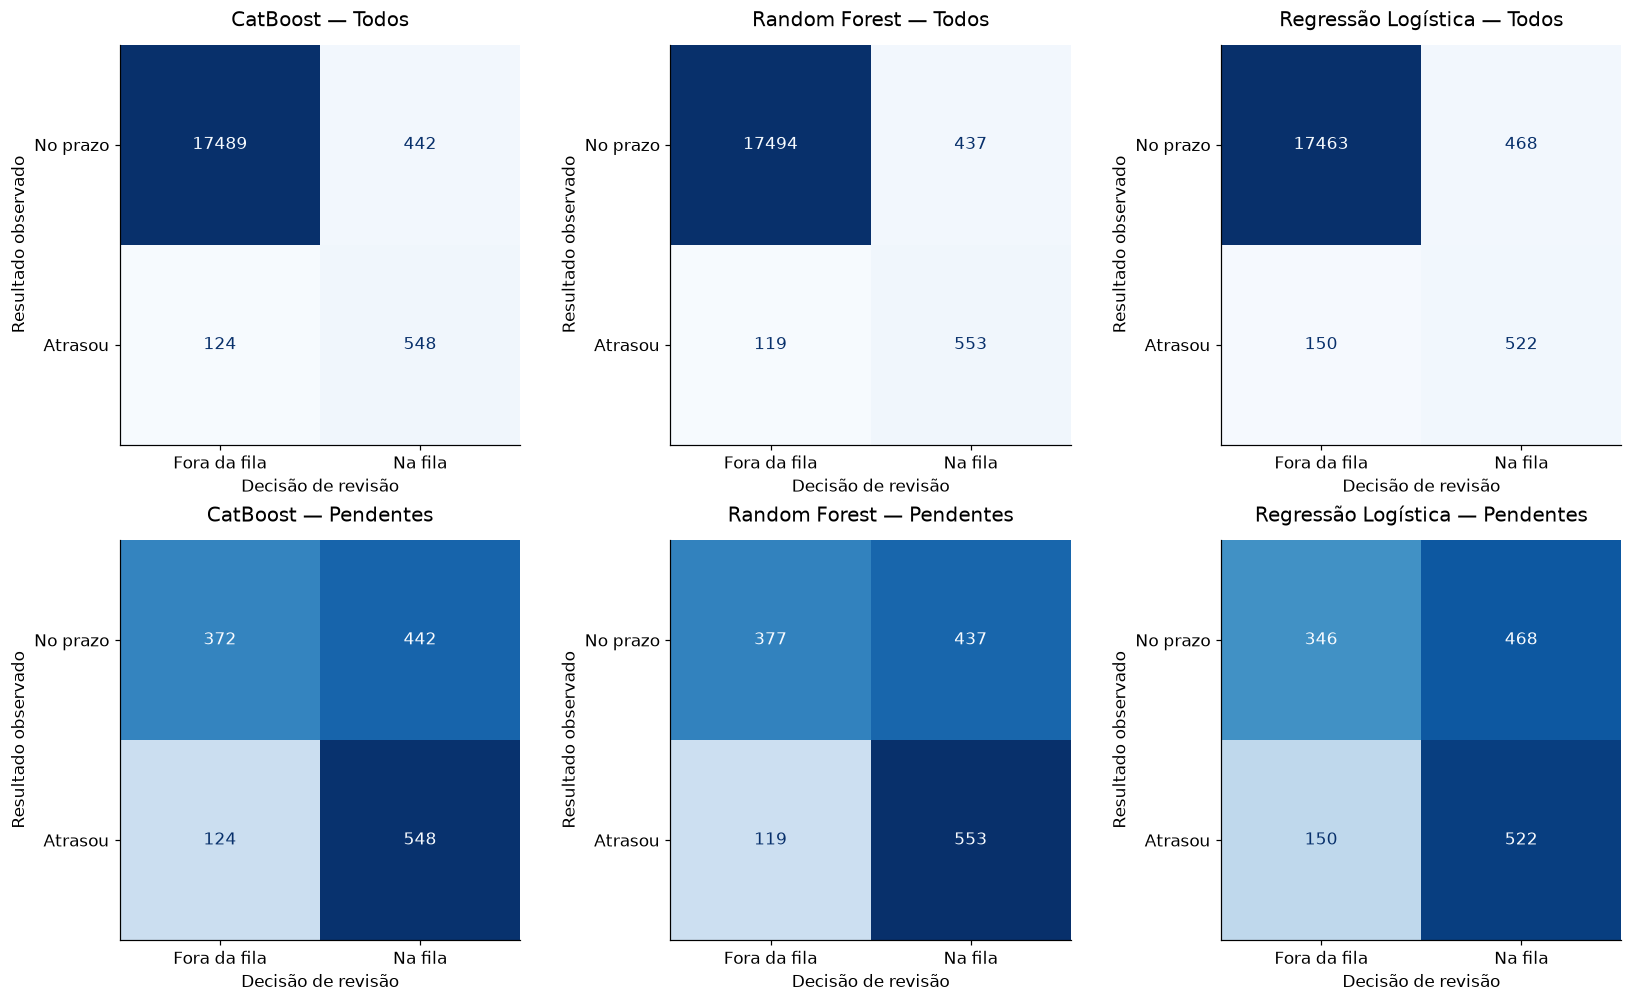

In [26]:
fig, eixos = plt.subplots(2, 3, figsize=(15, 9), layout="constrained")
for linha, (mascara, grupo) in enumerate([
    (np.ones(len(indice_teste), dtype=bool), "Todos"), (ativos_teste, "Pendentes")]):
    matrizes = [confusion_matrix(y[indice_teste][mascara], filas_teste_modelos[nome][mascara], labels=[0, 1]) for nome in modelos]
    maximo = max(m.max() for m in matrizes)
    for coluna, (nome, matriz) in enumerate(zip(modelos, matrizes)):
        ax = eixos[linha, coluna]
        ConfusionMatrixDisplay(matriz, display_labels=["No prazo", "Atrasou"]).plot(
            ax=ax, values_format="d", cmap="Blues", colorbar=False, im_kw={"vmin": 0, "vmax": maximo})
        ax.set(title=f"{nome} — {grupo}", xlabel="Decisão de revisão", ylabel="Resultado observado")
        ax.set_xticklabels(["Fora da fila", "Na fila"])
plt.show()


### 9.2. Precision–Recall: comparar os rankings

As três curvas usam exatamente os mesmos pedidos pendentes. A linha horizontal é
a proporção de atrasos nesse grupo. Os pontos marcam a política de fila diária;
como cada dia tem seu próprio corte, podem não estar sobre a curva de limiar único.

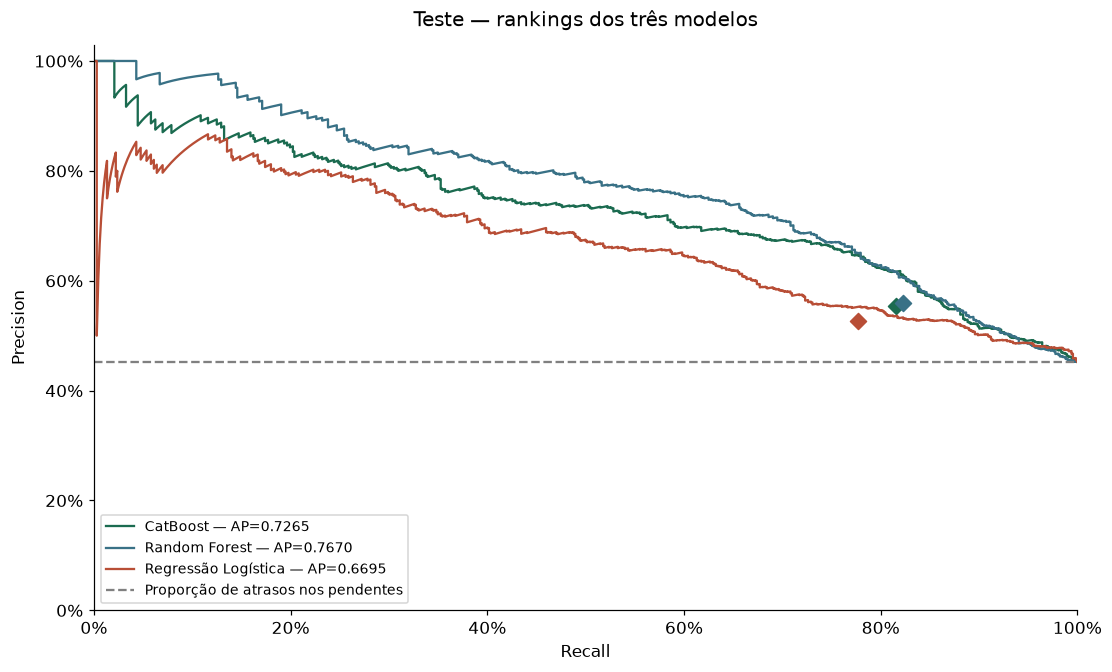

In [27]:
fig, ax = plt.subplots(figsize=(10, 6), layout="constrained")
real_pendente = y[indice_teste][ativos_teste]
for nome in modelos:
    precisao, revocacao, _ = precision_recall_curve(real_pendente, scores_teste_modelos[nome][ativos_teste])
    m = tabela_teste.loc[nome]
    ax.plot(revocacao, precisao, color=CORES_MODELOS[nome], label=f"{nome} — AP={m.ap_pendentes:.4f}")
    ax.scatter(m.recall, m.precision, color=CORES_MODELOS[nome], marker="D", s=55)
ax.axhline(real_pendente.mean(), color="gray", linestyle="--", label="Proporção de atrasos nos pendentes")
ax.set(title="Teste — rankings dos três modelos", xlabel="Recall", ylabel="Precision", xlim=(0, 1), ylim=(0, 1.03))
ax.xaxis.set_major_formatter(PercentFormatter(1)); ax.yaxis.set_major_formatter(PercentFormatter(1))
ax.legend(loc="lower left", fontsize=9)
plt.show()


### 9.3. Comparação de métricas, estabilidade temporal e custo

Mesmo número de alertas não significa os mesmos pedidos selecionados. Comparamos
métricas sob essa capacidade e mostramos a diferença entre validação e teste;
essa diferença também reflete a mudança de população ao longo do tempo.

Capacidade: 990 alertas por modelo; 66.62% dos pendentes (arredondamento diário).
Tempo comum de seleção, separado dos fits finais: 6.45 s


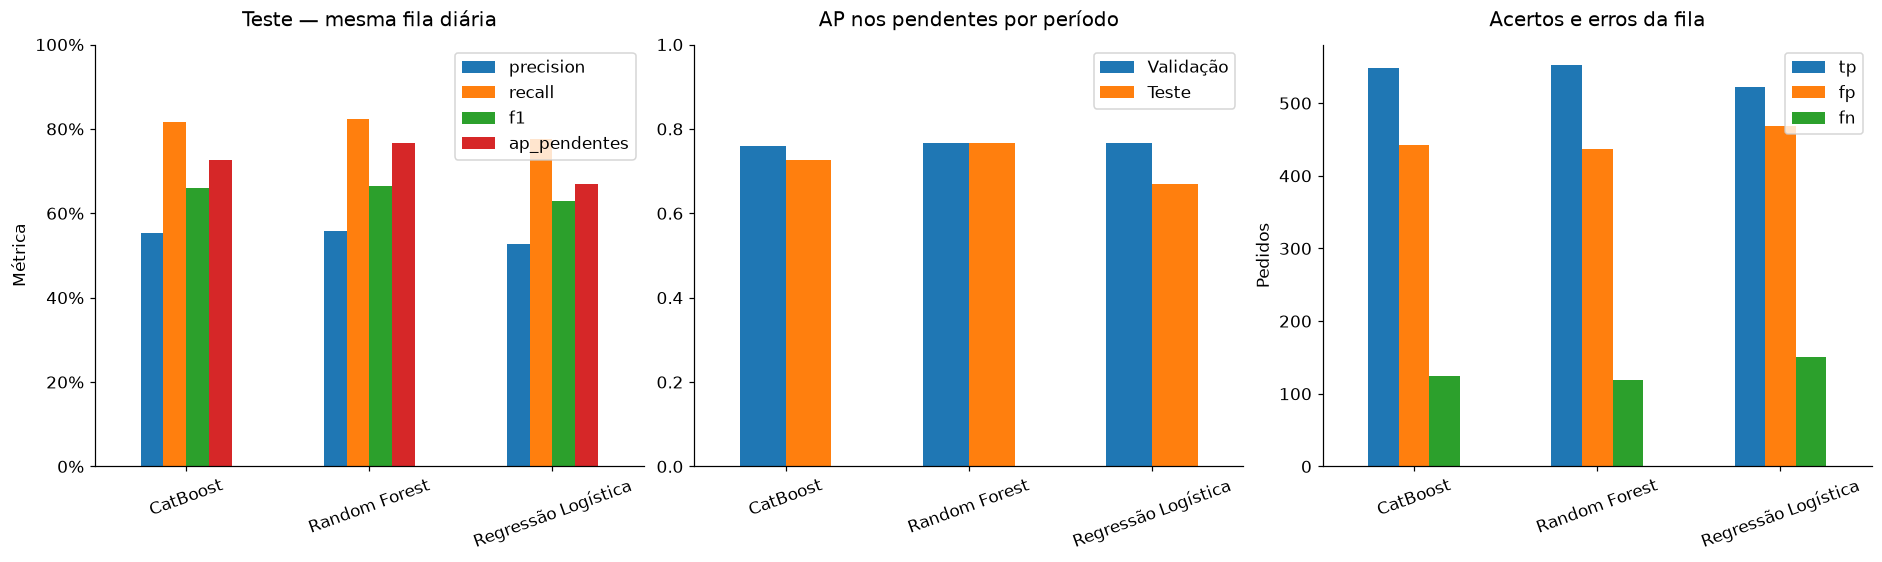

,precision,recall,f1,accuracy_total,accuracy_pendentes,ap_pendentes,Atributos originais,Entradas após preparação,Tempo de treino (s)
modelo,,,,,,,,,
CatBoost,0.5535,0.8155,0.6594,0.9696,0.6191,0.7265,77,77,6.5558
Random Forest,0.5586,0.8229,0.6655,0.9701,0.6258,0.7670,77,398,4.3483
Regressão Logística,0.5273,0.7768,0.6282,0.9668,0.5841,0.6695,77,398,0.8371


In [28]:
fig, eixos = plt.subplots(1, 3, figsize=(17, 5), layout="constrained")
tabela_teste[["precision", "recall", "f1", "ap_pendentes"]].plot.bar(ax=eixos[0], rot=20)
eixos[0].set(title="Teste — mesma fila diária", ylabel="Métrica", xlabel="", ylim=(0, 1))
eixos[0].yaxis.set_major_formatter(PercentFormatter(1))
pd.DataFrame({"Validação": tabela_validacao.ap_pendentes, "Teste": tabela_teste.ap_pendentes}).plot.bar(ax=eixos[1], rot=20)
eixos[1].set(title="AP nos pendentes por período", xlabel="", ylim=(0, 1))
tabela_teste[["tp", "fp", "fn"]].plot.bar(ax=eixos[2], rot=20)
eixos[2].set(title="Acertos e erros da fila", ylabel="Pedidos", xlabel="")
plt.show()
comparacao_final = tabela_teste[COLUNAS_METRICAS].join(tabela_treino)
display(comparacao_final.round(4))
print(f"Capacidade: {int(tabela_teste.fila.iloc[0])} alertas por modelo; "
      f"{tabela_teste.fila_pendentes.iloc[0]:.2%} dos pendentes (arredondamento diário).")
print("Tempo comum de seleção, separado dos fits finais:", round(tempo_selecao, 2), "s")


### 9.4. Importâncias do CatBoost final e comparação com o 03

O dicionário da seção 6.7 descreve exatamente o top 20 do 03. O gráfico abaixo é o
top 20 **do novo CatBoost após o drop**, que pode mudar. A tabela de referência
permite comparar os mesmos vinte atributos antes/depois sem substituir sua origem.

Importâncias são relativas a cada modelo; não medem efeito causal nem direção do efeito.


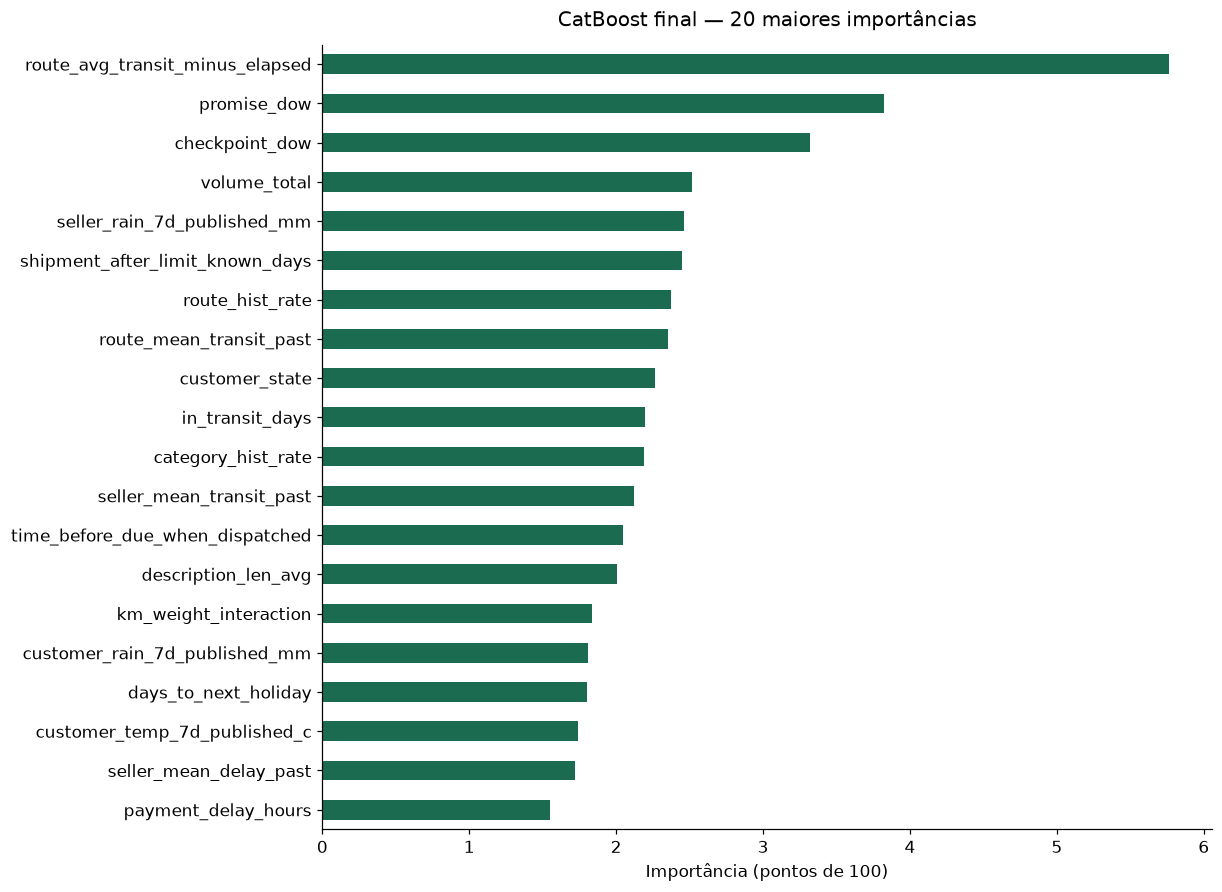

,Importância no 03,Importância após seleção,Mantida em X
route_avg_transit_minus_elapsed,5.773502,5.766345,True
checkpoint_dow,3.746604,3.317628,True
shipment_after_limit_known_days,3.420261,2.445316,True
promise_dow,3.120040,3.821100,True
volume_total,2.965995,2.517784,True
seller_mean_transit_past,2.545930,2.119750,True
seller_rain_7d_published_mm,2.249107,2.462137,True
customer_state,2.246123,2.265977,True
seller_temp_7d_published_c,2.000272,1.538130,True
category_hist_rate,1.921693,2.189183,True


In [29]:
importancias = pd.Series(modelo.get_feature_importance(), index=modelo.feature_names_).sort_values()
assert importancias.index.difference(X.columns).empty
fig, ax = plt.subplots(figsize=(11, 8), layout="constrained")
importancias.tail(20).plot.barh(ax=ax, color=CORES["modelo"])
ax.set(title="CatBoost final — 20 maiores importâncias", xlabel="Importância (pontos de 100)")
plt.show()
comparacao_top20 = top20_referencia_03.to_frame()
comparacao_top20["Importância após seleção"] = importancias.reindex(comparacao_top20.index)
comparacao_top20["Mantida em X"] = comparacao_top20.index.isin(X.columns)
display(comparacao_top20.round(6))
print("Importâncias são relativas a cada modelo; não medem efeito causal nem direção do efeito.")


## 10. Salvar e conferir os resultados

Salvamos o primeiro CatBoost (auditoria), os três modelos finais, os preprocessadores
dentro dos pipelines, a seleção de colunas, o dataset reduzido com alvo/metadados,
as previsões dos três modelos e as tabelas de avaliação. A seleção é refeita de modo
determinístico em Executar Tudo; para inferência use as colunas registradas no JSON.
Os arquivos ficam em uma pasta exclusiva desta execução. A aplicação segue usando
seu modelo anterior. O alvo `atrasou` nunca deve ser passado como entrada ao modelo.

In [30]:
SAIDA.mkdir(parents=True, exist_ok=False)
modelo_inicial.save_model(str(SAIDA / "catboost_inicial_111.cbm"))
modelo.save_model(str(SAIDA / "catboost_selecionado.cbm"))
joblib.dump(modelos["Random Forest"], SAIDA / "random_forest_pipeline.joblib")
joblib.dump(modelos["Regressão Logística"], SAIDA / "regressao_logistica_pipeline.joblib")
tabela_selecao.to_csv(SAIDA / "selecao_atributos.csv", index_label="coluna")
comparacao_top20.to_csv(SAIDA / "top20_referencia_03.csv", index_label="coluna")
tabela_validacao.to_csv(SAIDA / "metricas_validacao.csv")
tabela_teste.to_csv(SAIDA / "metricas_teste.csv")
comparacao_final.to_csv(SAIDA / "comparacao_modelos.csv")
ablacao.to_csv(SAIDA / "ablacao_catboost_validacao.csv")
X.to_csv(SAIDA / "pedidos.csv", index=False)  # somente atributos selecionados
dataset = X.copy()
dataset.insert(0, "order_id", pedidos_d1.order_id)
dataset["checkpoint_at"] = pedidos_d1.checkpoint_at
dataset["atrasou"] = y
dataset["pendente"] = pendente
dataset["uso"] = "excluido_do_ajuste_e_avaliacao"
for nome, idx in indices.items():
    dataset.loc[idx, "uso"] = nome
dataset.to_parquet(SAIDA / "dataset_analitico_d1.parquet", index=False)
previsoes = pd.DataFrame({"order_id": pedidos_d1.order_id.iloc[indice_teste].to_numpy(),
    "checkpoint_at": pedidos_d1.checkpoint_at.iloc[indice_teste].to_numpy(),
    "atrasou": y[indice_teste], "pendente": ativos_teste})
for nome, sufixo in [("CatBoost", "catboost"), ("Random Forest", "random_forest"), ("Regressão Logística", "linear")]:
    previsoes[f"score_{sufixo}"] = scores_teste_modelos[nome]
    previsoes[f"prioridade_{sufixo}"] = filas_teste_modelos[nome]
previsoes.to_csv(SAIDA / "previsoes_teste.csv", index=False)
reaberto_cb = CatBoostClassifier()
reaberto_cb.load_model(str(SAIDA / "catboost_selecionado.cbm"))
reabertos = {"CatBoost": reaberto_cb,
    "Random Forest": joblib.load(SAIDA / "random_forest_pipeline.joblib"),
    "Regressão Logística": joblib.load(SAIDA / "regressao_logistica_pipeline.joblib")}
for nome, est in reabertos.items():
    scores_reabertos = pontuar(est, indice_teste)
    np.testing.assert_allclose(scores_reabertos, scores_teste_modelos[nome], atol=1e-12, rtol=0)
    np.testing.assert_array_equal(fila_diaria(scores_reabertos, indice_teste), filas_teste_modelos[nome])
    print(nome, "recarregado: scores e fila conferidos.")
for caminho, digest in hashes_antes.items():
    assert sha256(caminho) == digest, f"Arquivo anterior alterado: {caminho}"
for caminho in [ARQUIVO_OLIST, ARQUIVO_RODOVIAS]:
    assert sha256(caminho) == hashes_fontes[caminho.name]
print("Fontes, notebooks anteriores e modelo da aplicação preservados.")


CatBoost recarregado: scores e fila conferidos.
Random Forest recarregado: scores e fila conferidos.
Regressão Logística recarregado: scores e fila conferidos.
Fontes, notebooks anteriores e modelo da aplicação preservados.


In [31]:
registro = {"execucao_utc": EXECUCAO, "python": sys.version, "versoes": VERSOES,
    "hashes_fontes": hashes_fontes, "parametros_catboost": PARAMETROS,
    "parametros_random_forest": PARAMETROS_RF, "parametros_linear": PARAMETROS_LINEAR,
    "limiar_importancia": LIMIAR_IMPORTANCIA, "regra_remocao": "importancia < limiar; somente treino",
    "colunas_removidas": colunas_removidas, "colunas_entrada": X.columns.tolist(),
    "categoricas": categoricas, "numericas": numericas,
    "checkpoint": "D-1 00:00", "fracao_diaria_pendentes": FRACAO_FILA,
    "inicio_validacao": str(inicio_validacao), "inicio_teste": str(inicio_teste),
    "n_treino": len(indice_treino), "tempos_treino_segundos": tempos_treino,
    "tempo_selecao_segundos": tempo_selecao, "modelo_escolhido_validacao": modelo_escolhido_validacao,
    "criterio_escolha": "maior AP nos pendentes da validacao",
    "validacao": tabela_validacao.to_dict(orient="index"), "teste": tabela_teste.to_dict(orient="index"),
    "ablacao_validacao": ablacao.to_dict(orient="index"), "regra_escolhida": melhor_regra,
    "teste_regra": metricas_regra, "coberturas": coberturas, "teste_reutilizado": True,
    "cota_pos_exploracao": True, "dados_sinteticos": False, "arquivos_anteriores_inalterados": True}
(SAIDA / "resultados.json").write_text(json.dumps(registro, ensure_ascii=False, indent=2), encoding="utf-8")
escolhido = tabela_teste.loc[modelo_escolhido_validacao]
display(Markdown(f"""### Resultado para apresentar
- **{len(X_treino):,} pedidos de treino**; **{X_completo.shape[1]} → {X.shape[1]} atributos** após seleção.
- CatBoost: variação de AP na validação após o drop = **{delta_ap:+.4f}**.
- Modelo escolhido pela validação: **{modelo_escolhido_validacao}**.
- No teste, esse modelo encontrou **{int(escolhido.tp)} de {int(escolhido.atrasos)} atrasos** em **{int(escolhido.fila)} revisões**.
- Precision **{escolhido.precision:.2%}**, recall **{escolhido.recall:.2%}**, F1 **{escolhido.f1:.2%}**, AP **{escolhido.ap_pendentes:.4f}**.
- Tempos e métricas dos três modelos estão na tabela comparativa, sem trocar a escolha após ver o teste.
- Resultados exploratórios: não medimos redução real de atrasos, retorno financeiro ou superioridade estatística.
"""))
print("Arquivos desta execução:", SAIDA)


Arquivos desta execução: C:\Users\cpedr\Documents\Documentos\TCS\projeto\EntregaCerta-AI\Modelos\notebook04_ver07\20261118_021029_c7d60d


### Resultado para apresentar
- **5,655 pedidos de treino**; **111 → 77 atributos** após seleção.
- CatBoost: variação de AP na validação após o drop = **+0.0036**.
- Modelo escolhido pela validação: **Random Forest**.
- No teste, esse modelo encontrou **553 de 672 atrasos** em **990 revisões**.
- Precision **55.86%**, recall **82.29%**, F1 **66.55%**, AP **0.7670**.
- Tempos e métricas dos três modelos estão na tabela comparativa, sem trocar a escolha após ver o teste.
- Resultados exploratórios: não medimos redução real de atrasos, retorno financeiro ou superioridade estatística.


## Roteiro de encerramento da apresentação

1. **Problema e dados:** priorizar pedidos pendentes em D−1; sete tabelas Olist e fontes externas.
2. **Tratamento:** uma linha por pedido, junções validadas e históricos limitados ao que era conhecido.
3. **EDA:** proporção de atrasos muda ao condicionar a pendentes; sazonalidade, distribuição e ausências.
4. **Engenharia:** explicar os vinte sinais do CatBoost do 03 com as fórmulas e as chaves da seção 6.
5. **Seleção:** primeiro CatBoost, corte fixo de 0,4 ponto, drop real em X, avaliação do efeito na validação.
6. **Modelos:** árvores em boosting, floresta e classificador linear; mesmas entradas de origem e mesmo período de treino.
7. **Avaliação:** matrizes, Precision–Recall, AP, F1, alertas e tempo; escolha definida na validação.
8. **Limites:** entregues com desfecho conhecido, seleção orientada pelo CatBoost, ausência de busca equivalente
   de hiperparâmetros, proxies geográficos/climáticos, rede rodoviária posterior e teste já reutilizado.

Próximo estudo: um período realmente novo, protocolo congelado e avaliação operacional.
Não continuar alterando cortes com base no teste histórico até obter a métrica desejada.
O backend não é modificado por este notebook.